# Ecuación del Calor en polares (2D)

Dado

$$
\Omega = \{(x,y) : r_1^2 < x^2 + y^2 < r_2^2\},
$$

y

$$
f : \Omega \times [0, T] \to \mathbb{R}
$$

se quiere hallar

$$
u : \Omega \times [0,T] \to \mathbb{R}
$$

tal que satisface la ecuación del calor en dos dimensiones:

$$
\frac{\partial u}{\partial t} = a\,\Delta u + f(x,y,t), \qquad (x,y) \in \Omega,\; t \in (0,T).
$$

Con condiciones de contorno Dirichlet homogéneas:

$$
u(x,y,t) = 0 \qquad \text{en } \partial\Omega,\; t \in (0,T),
$$

y condición inicial

$$
u(x,y,0) = g(x,y), \qquad (x,y) \in \Omega.
$$

El laplaciano en polares es

$$
\Delta u = \frac{\partial^2 u}{\partial r^2} + \frac{1}{r}\frac{\partial u}{\partial r} + \frac{1}{r^2}\frac{\partial^2 u}{\partial \theta^2}.
$$

## Objetivos y consignas

### Ejercicio 1
Deducir esquemas análogos a los de calor en coordenadas cartesianas, pero ahora para el problema en coordenadas polares. La idea es discretizar el laplaciano polar usando diferencias centradas en $r$ y $\theta$ y obtener sus versiones explícita e implícita.

### Ejercicio 2
Implementar ambos métodos para $r_1 > 0$, usando coordenadas polares, con pasos espaciales $\Delta r$ y $\Delta \theta$, paso temporal $\Delta t$, tiempo final $T$, coeficiente de difusión $a$, dato inicial $g$ y fuente $f$. El resultado debe visualizarse mediante un gráfico o una animación que muestre la evolución temporal de la solución.

### Ejercicio 3 (adicional)
Analizar la estabilidad de ambos esquemas mediante el método de von Neumann, "congelando" localmente el coeficiente $1/r_i$. Debe determinarse la condición sobre $\Delta t$ en función de $\Delta r$, $\Delta \theta$, $r$ y $a$ para que el esquema explícito sea estable, y verificar que el esquema implícito es incondicionalmente estable. Además, se recomienda corroborar experimentalmente ambos resultados.

### Referencia del esquema en cartesianas

Como base de comparación, se recuerdan los esquemas clásicos para la ecuación del calor en coordenadas cartesianas:

$$
\Delta_h u_{i,j} = \frac{u_{i+1,j} - 2u_{i,j} + u_{i-1,j}}{\Delta x^2} + \frac{u_{i,j+1} - 2u_{i,j} + u_{i,j-1}}{\Delta y^2}.
$$

y las versiones de avance temporal:

$$
\frac{u_{i,j}^{n+1} - u_{i,j}^{n}}{\Delta t} = a\,\Delta_h u_{i,j}^{n+1} + f_{i,j}^{n},
$$

para el esquema implícito, y

$$
\frac{u_{i,j}^{n+1} - u_{i,j}^{n}}{\Delta t} = a\,\Delta_h u_{i,j}^{n} + f_{i,j}^{n},
$$

para el esquema explícito.

### Datos de ejemplo sugeridos

Se proponen varios ejemplos para probar la implementación:

- $g(r,\theta) = 0$
- $g(r,\theta) = (r-r_1)(r_2-r)$
- $g(r,\theta) = \mathbf{1}_{[r_1,r_2]\times[\theta_1,\theta_2]}$

para la condición inicial, y

- $f(r,\theta,t)=0$
- $f(r,\theta,t)=(r-r_1)(r_2-r)$
- $f(r,\theta,t)=(r-r_1)(r_2-r)e^{-t}$

con distintos valores del $a$:

$$
a = 1, \qquad a = 0.1, \qquad a = 10.
$$

### Discretización en coordenadas polares

Dominio $r\in[r_{in},r_{out}]$, $\theta\in[0,2\pi)$ periódico.

- $r_i = r_{in} + i\Delta r$, $i=0,\ldots,N+1$, con $\Delta r=(r_{\rm out}-r_{\rm in})/(N+1)$,
- $\theta_j = j\Delta\theta$, $j=0,\ldots,N-1$, con $\Delta\theta=2\pi/N$,
- $t_n=n\Delta t$.

Notemos que estamos asumiendo una malla cuadrada, solo por simplicidad.

Con $U^n_{i,j}\approx u(r_i,\theta_j,t_n)$ y diferencias centradas,

$$
(L_hU)_{i,j}=\alpha_i^-U_{i-1,j}+\alpha_i^+U_{i+1,j}+\beta_i\,(U_{i,j-1}+U_{i,j+1})+\gamma_iU_{i,j},
$$

con

- $ \alpha_i^\pm=\frac{1}{\Delta r^2}\pm\frac{1}{2r_i\Delta r}, $
- $ \beta_i=\frac{1}{r_i^2\Delta\theta^2}, $
- $ \gamma_i=-\frac{2}{\Delta r^2}-2\beta_i. $


### Condiciones inicial y de contorno

- $U^0_{i,j}=g(r_i,\theta_j),$
- $U^n_{0,j}=U^n_{N+1,j}=0$.
- En $\theta$ la malla es periódica: $U_{i,-1}=U_{i,N-1}$ y $U_{i,N}=U_{i,0}$.

### Esquema implícito

$$
\frac{U^{n+1}_{i,j}-U^n_{i,j}}{\Delta t}=a\,(L_hU^{n+1})_{i,j}+f(r_i,\theta_j,t_{n+1}),
$$

es decir, para $i=1,\ldots,N$:

$$
(1-a\Delta t\,\gamma_i)U^{n+1}_{i,j}-a\Delta t\,\alpha_i^+U^{n+1}_{i+1,j}-a\Delta t\,\alpha_i^-U^{n+1}_{i-1,j}
-a\Delta t\,\beta_i\,(U^{n+1}_{i,j+1}+U^{n+1}_{i,j-1})=U^n_{i,j}+\Delta t\,f^{n+1}_{i,j}.
$$

### Forma matricial

Con $U^n\in\mathbb{R}^{N\times N}$ (filas $i=1,\dots,N$, columnas $j=0,\dots,N-1$) y $F^{n+1}_{ij}=f(r_i,\theta_j,t_{n+1})$:

$$
A\,U^{n+1}+\mathcal{B}\,U^{n+1}\,T=U^n+\Delta t\,F^{n+1}.
$$

donde

$$
A=
\begin{pmatrix}
1-a\Delta t\gamma_1 & -a\Delta t\,\alpha_1^{+} & & \\
-a\Delta t\,\alpha_2^{-} & 1-a\Delta t\gamma_2 & -a\Delta t\,\alpha_2^{+} & \\
& \ddots & \ddots & \ddots \\
& & -a\Delta t\,\alpha_{N}^{-} & 1-a\Delta t\gamma_{N}
\end{pmatrix},
$$

$$
T=-a\Delta t
\begin{pmatrix}
0 & 1 & & & 1 \\
1 & 0 & 1 & & \\
& \ddots & \ddots & \ddots & \\
& & 1 & 0 & 1 \\
1 & & & 1 & 0
\end{pmatrix},
$$

y $\mathcal{B}=\operatorname{diag}(\beta_1,\dots,\beta_{N})$. Es importante notar que los $1$ en las esquinas de $T$ ($T_{1,N}=T_{N,1}$) cierran la periodicidad en $\theta$. En $A$ los vecinos $i=0,N+1$ valen $0$ (Dirichlet homogéneo) y por eso no aparecen.

### Paso temporal con Kronecker

Con $u^n=\mathrm{vec}(U^n)\in\mathbb{R}^{N^2}$ (apilando columnas, la entrada $(i,j)$ queda en la posición $i+jN$) y $T^T=T$:

$$
K\,u^{n+1}=u^n+\Delta t\,f^{n+1},\qquad
K=I_N\otimes A+T\otimes\mathcal{B}\in\mathbb{R}^{N^2\times N^2}.
$$

$K$ es bloque-tridiagonal periódica, con bloques de $N\times N$:

$$
K=
\begin{pmatrix}
A & -a\Delta t\,\mathcal{B} & & -a\Delta t\,\mathcal{B} \\
-a\Delta t\,\mathcal{B} & A & -a\Delta t\,\mathcal{B} & \\
& \ddots & \ddots & \ddots \\
-a\Delta t\,\mathcal{B} & & -a\Delta t\,\mathcal{B} & A
\end{pmatrix}.
$$

$K$ no depende de $n$, así que se calcula una sola vez.

### Esquema explícito


$$
\frac{U^{n+1}_{i,j}-U^n_{i,j}}{\Delta t}=a\,(L_hU^{n})_{i,j}+f(r_i,\theta_j,t_{n}),
$$

es decir, para $i=1,\ldots,N$:

$$
U^{n+1}_{i,j} = (1 + a \Delta t \gamma_i )U_{i,j}^{n} + a \Delta t \alpha_i^-U_{i-1,j}^{n} + a \Delta t \alpha_i^+U_{i+1,j}^{n} + a \Delta t \beta_i\,(U_{i,j-1}^{n} + U_{i,j+1}^{n}) + \Delta t f^{n}_{i,j} .
$$

matricialmente tenemos

$$ U^{n+1} = A U^{n} + B U^{n} T + \Delta t F^{n} $$

donde las matrices son como antes salvo que T tiene el "signo" opuesto y $A$ es de la forma

$$
A=
\begin{pmatrix}
1 + a\Delta t\gamma_1 & a\Delta t\,\alpha_1^{+} & & \\
a\Delta t\,\alpha_2^{-} & 1 + a\Delta t\gamma_2 & a\Delta t\,\alpha_2^{+} & \\
& \ddots & \ddots & \ddots \\
& & a\Delta t\,\alpha_{N}^{-} & 1 + a\Delta t\gamma_{N}
\end{pmatrix}.
$$



In [ ]:
using LinearAlgebra, SparseArrays
using CairoMakie

In [ ]:
# Parámetros del dominio y de la malla
const r1, r2 = 1.0, 2.0
const N      = 64
const dt     = 1e-3
const Tfinal = 0.5
const nsteps = round(Int, Tfinal / dt)

# Condiciones iniciales g(r,θ)
g_zero(r, θ)  = 0.0
g_parab(r, θ) = (r - r1) * (r2 - r)

# Indicadora de un rectangulito [ra,rb]×[θa,θb]
const ra, rb = 1.25, 1.75
const θa, θb = π/4, π/2
g_ind(r, θ) = (ra ≤ r ≤ rb && θa ≤ θ ≤ θb) ? 1.0 : 0.0


# Fuentes f(r,θ,t)
f_zero(r, θ, t)  = 0.0
f_parab(r, θ, t) = (r - r1) * (r2 - r)
f_exp(r, θ, t)   = (r - r1) * (r2 - r) * exp(-t)

f_exp (generic function with 1 method)

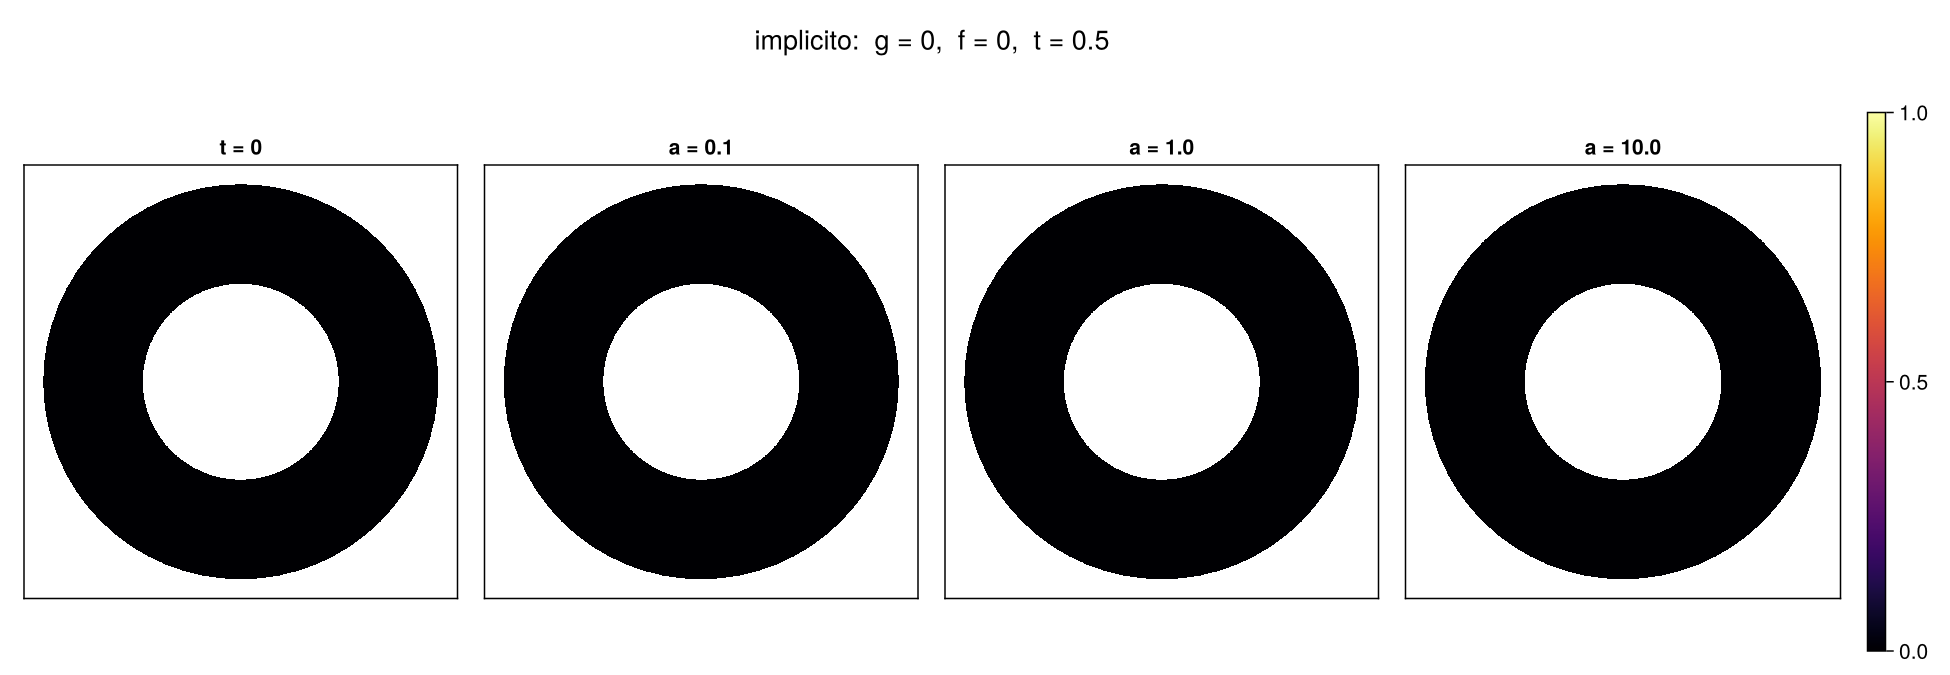

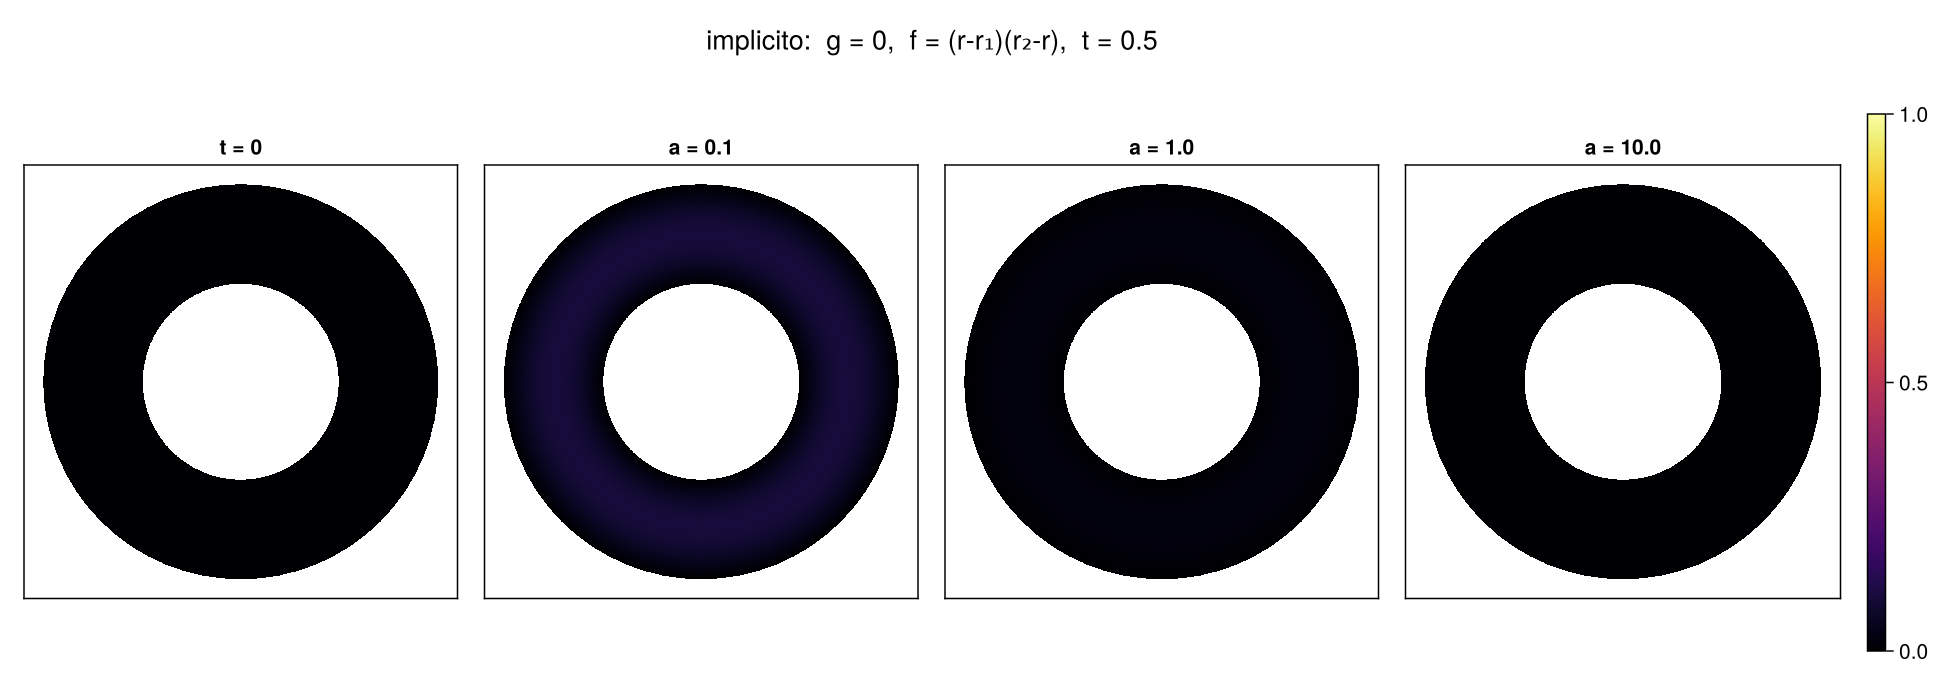

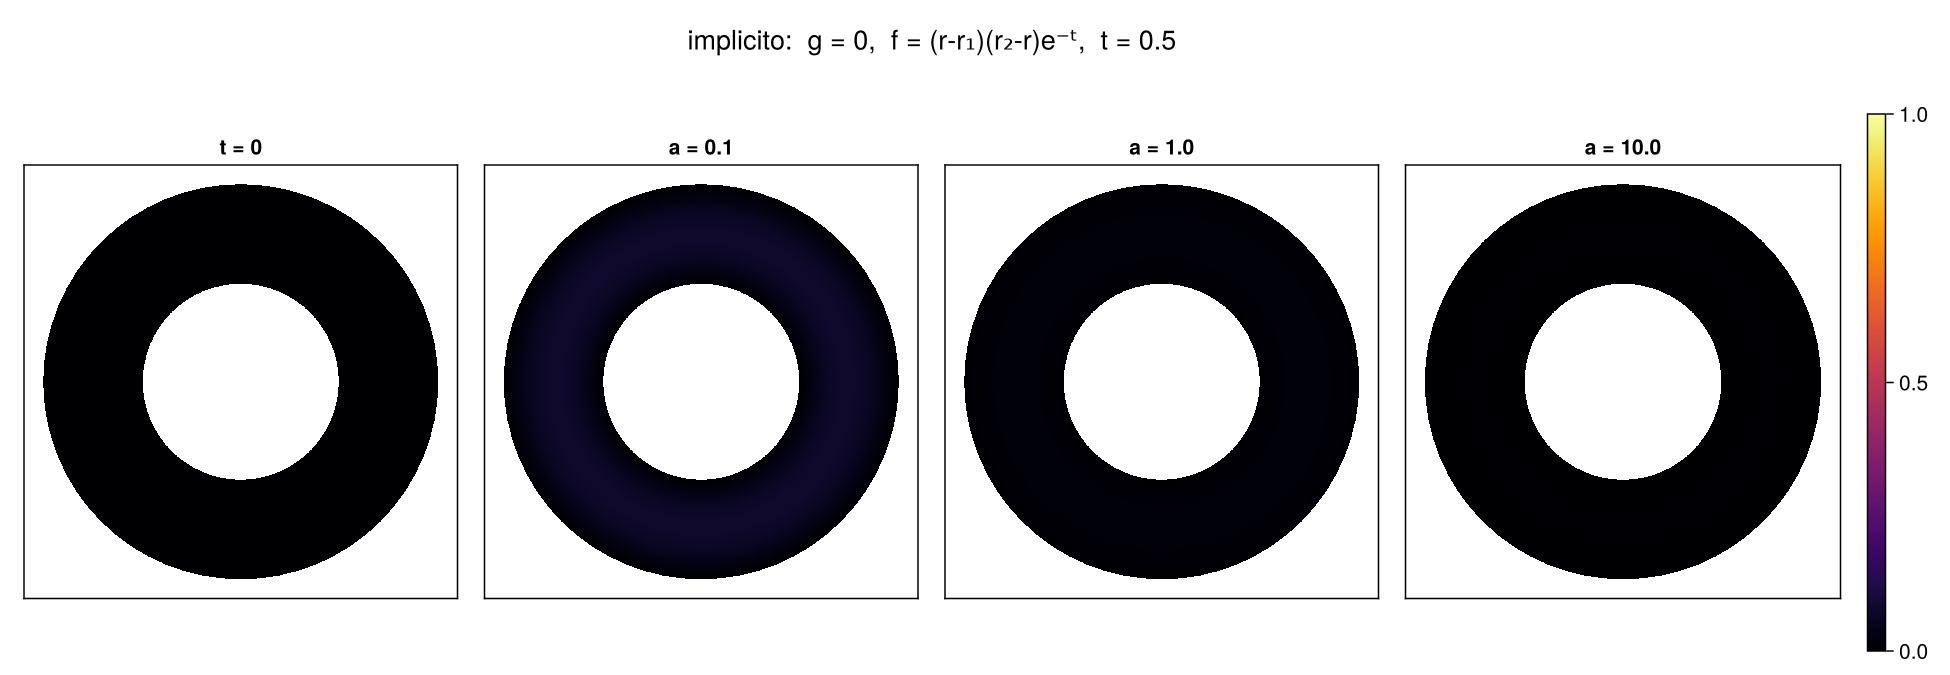

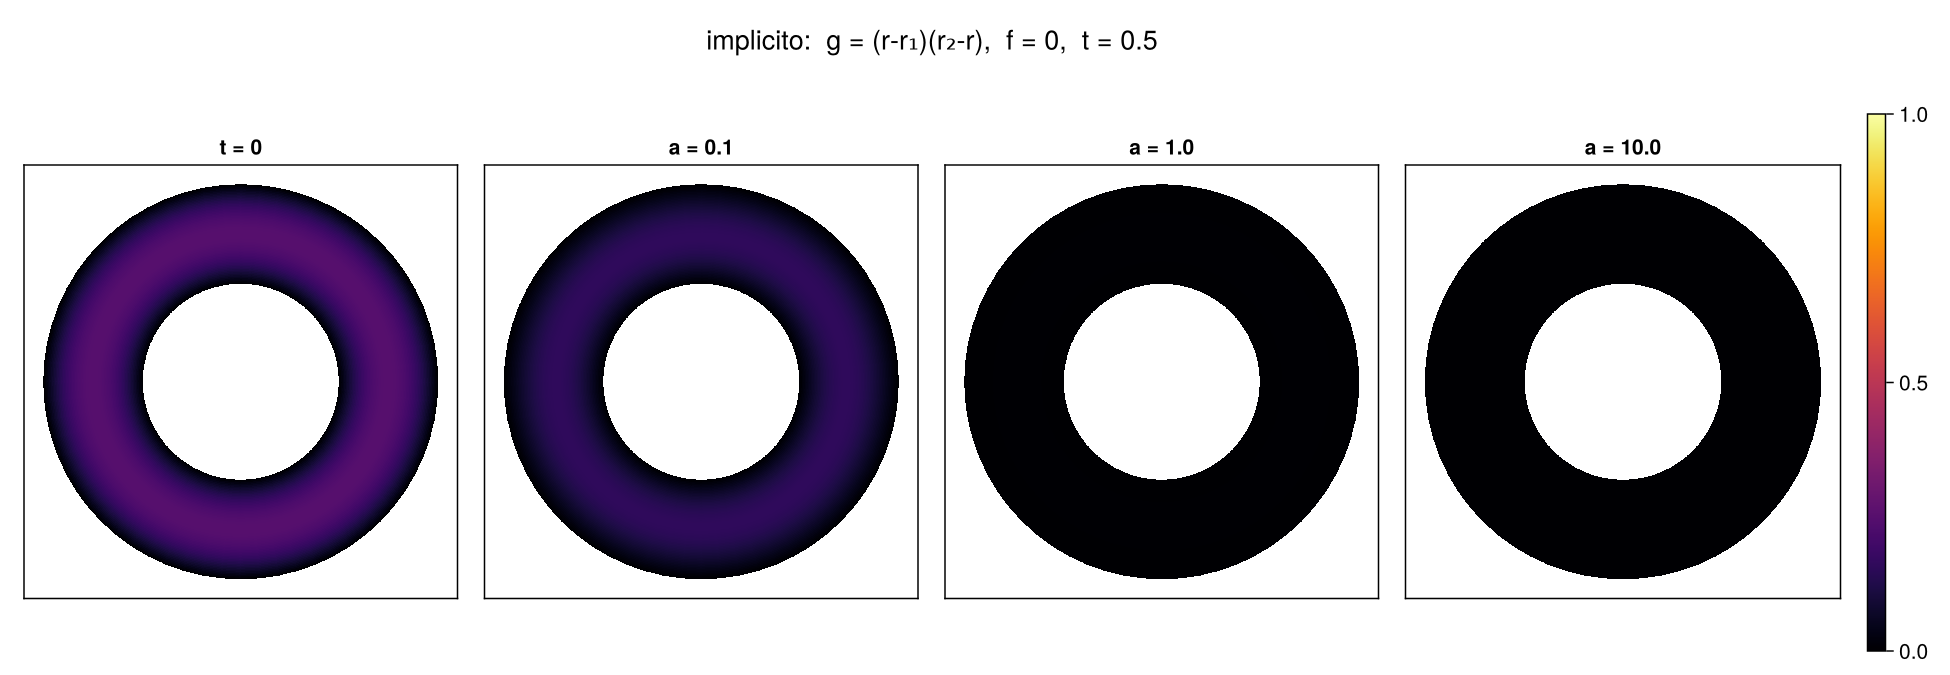

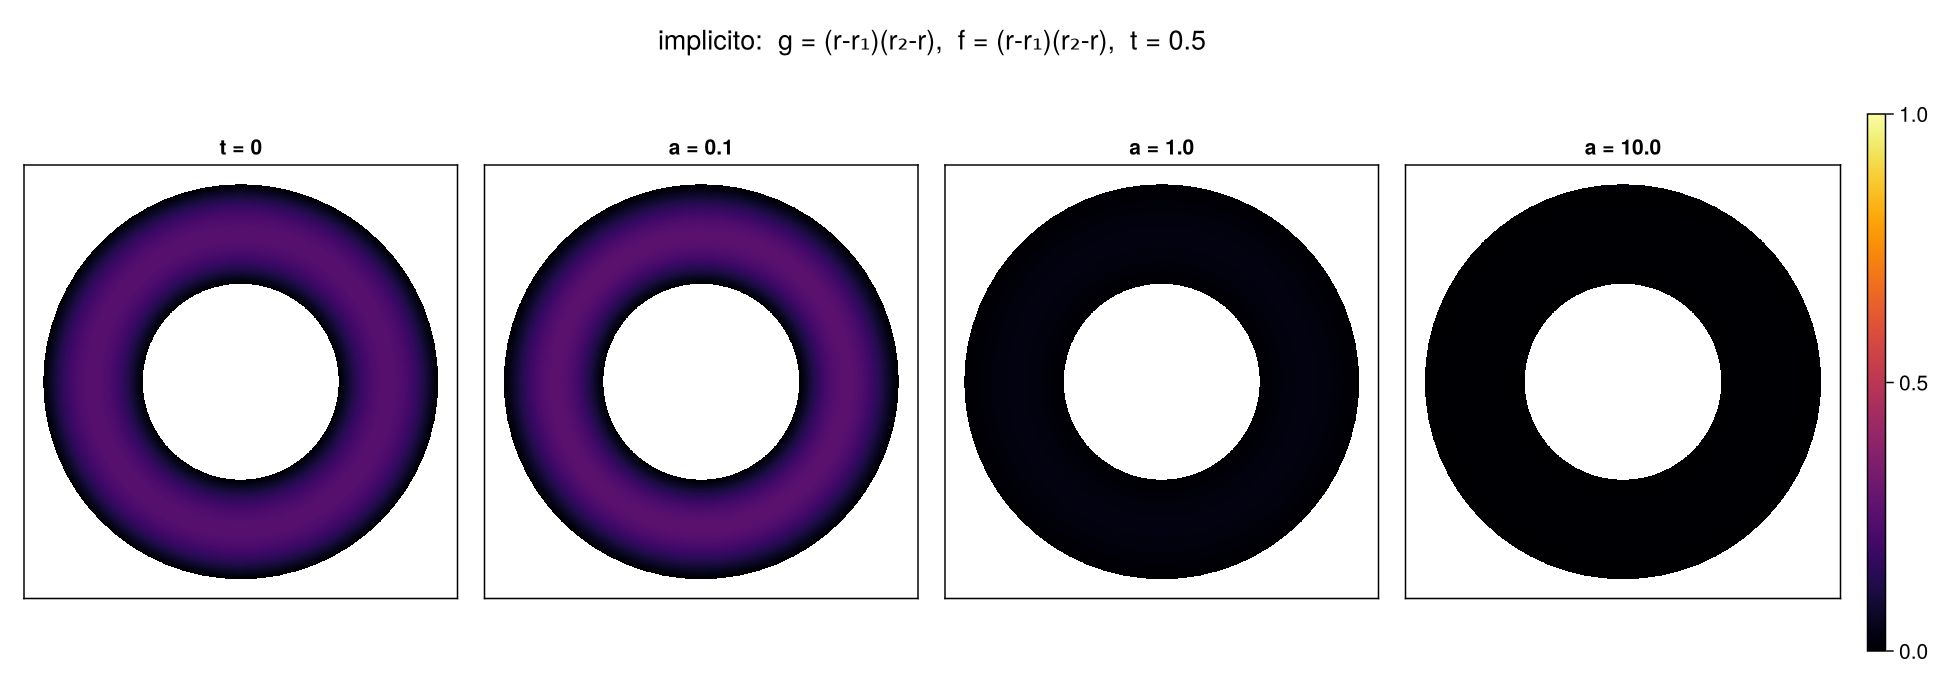

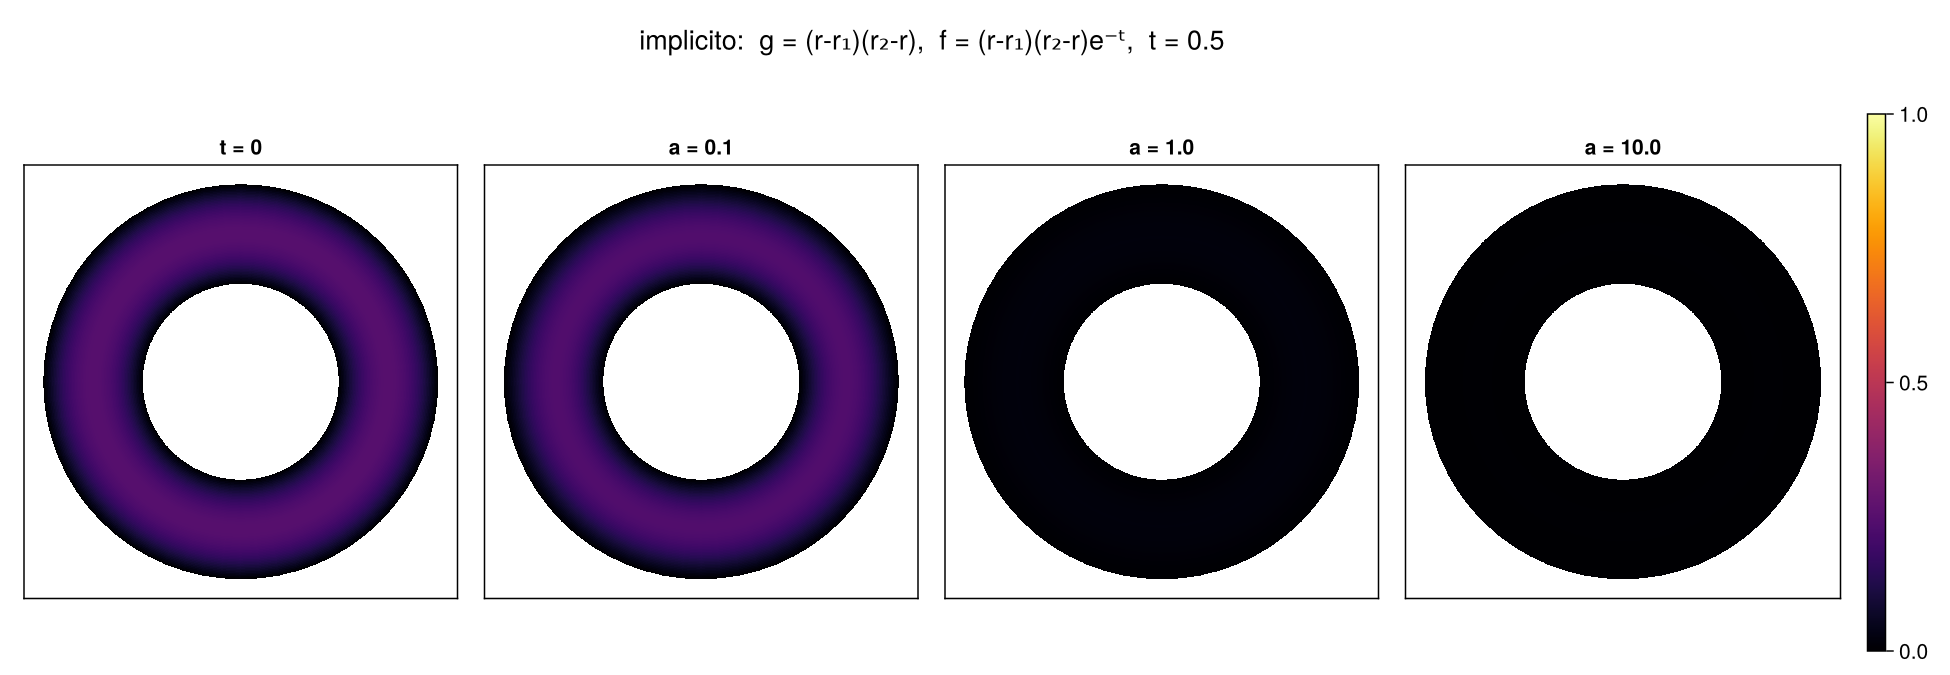

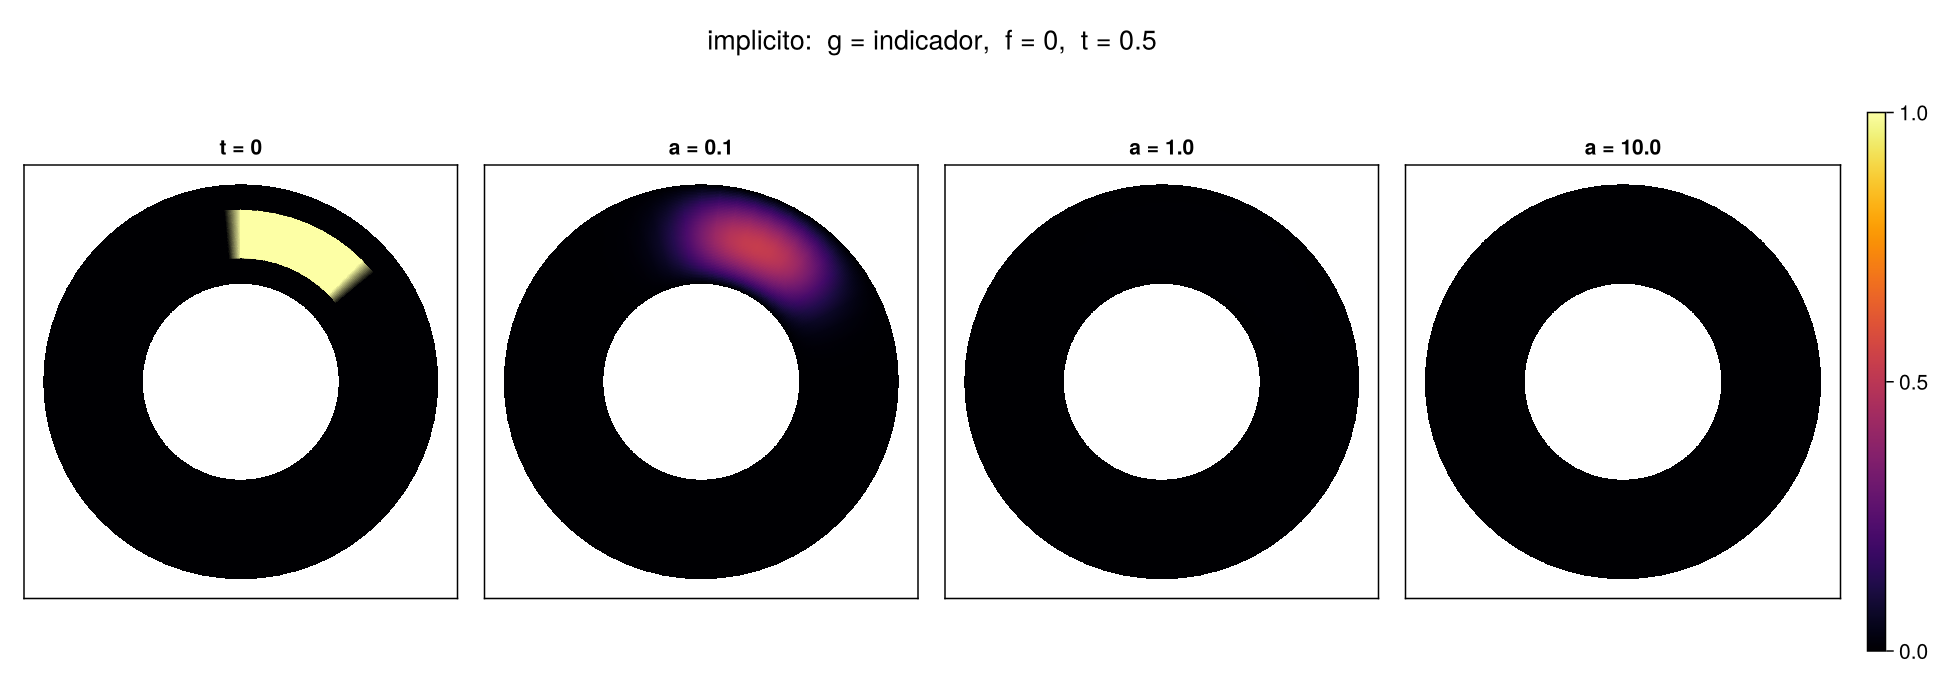

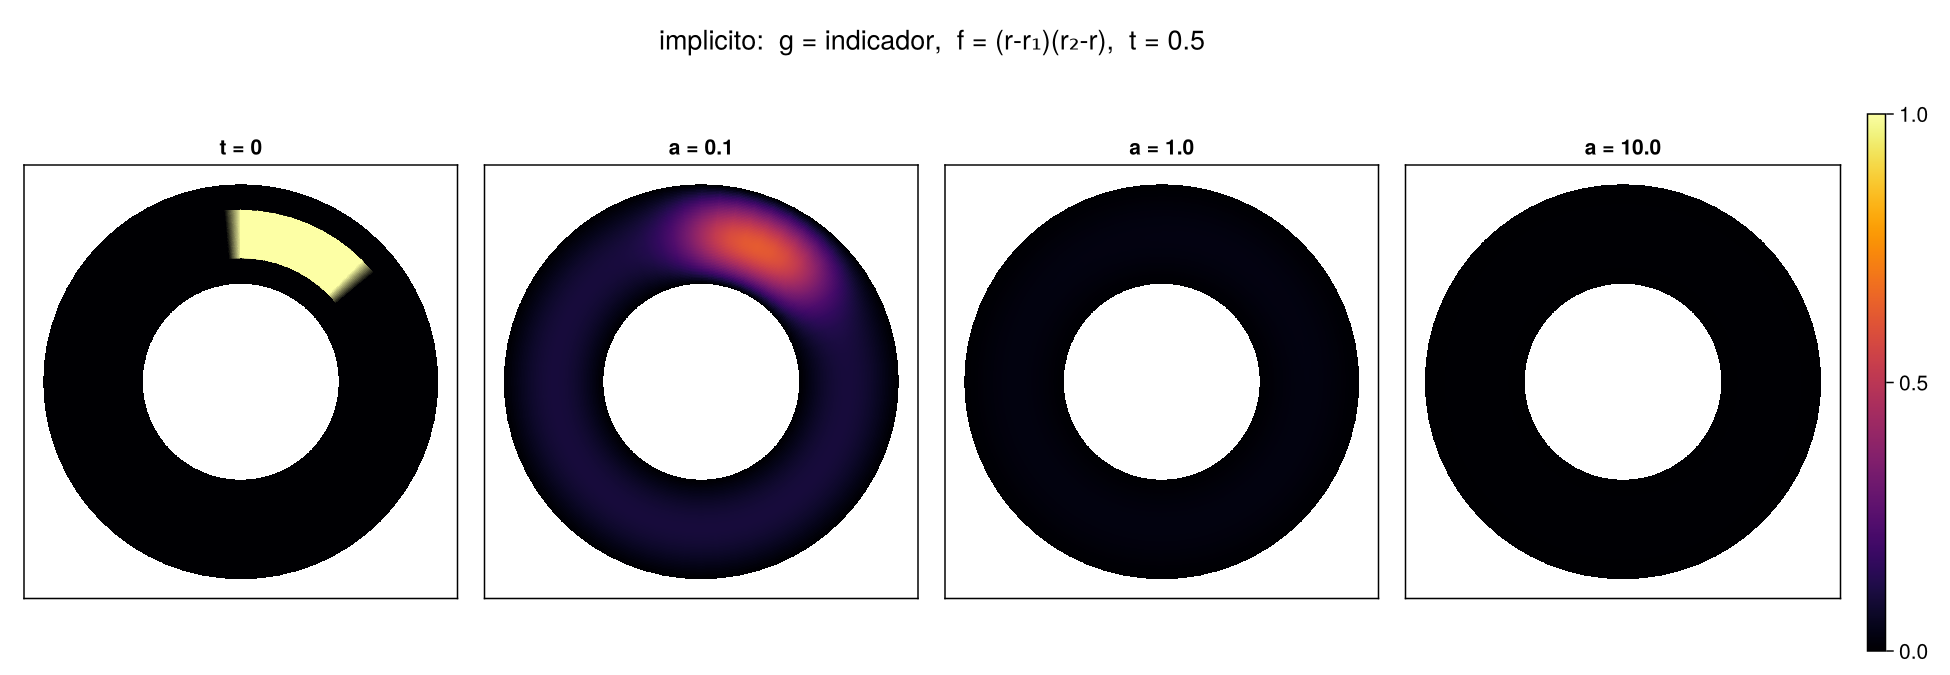

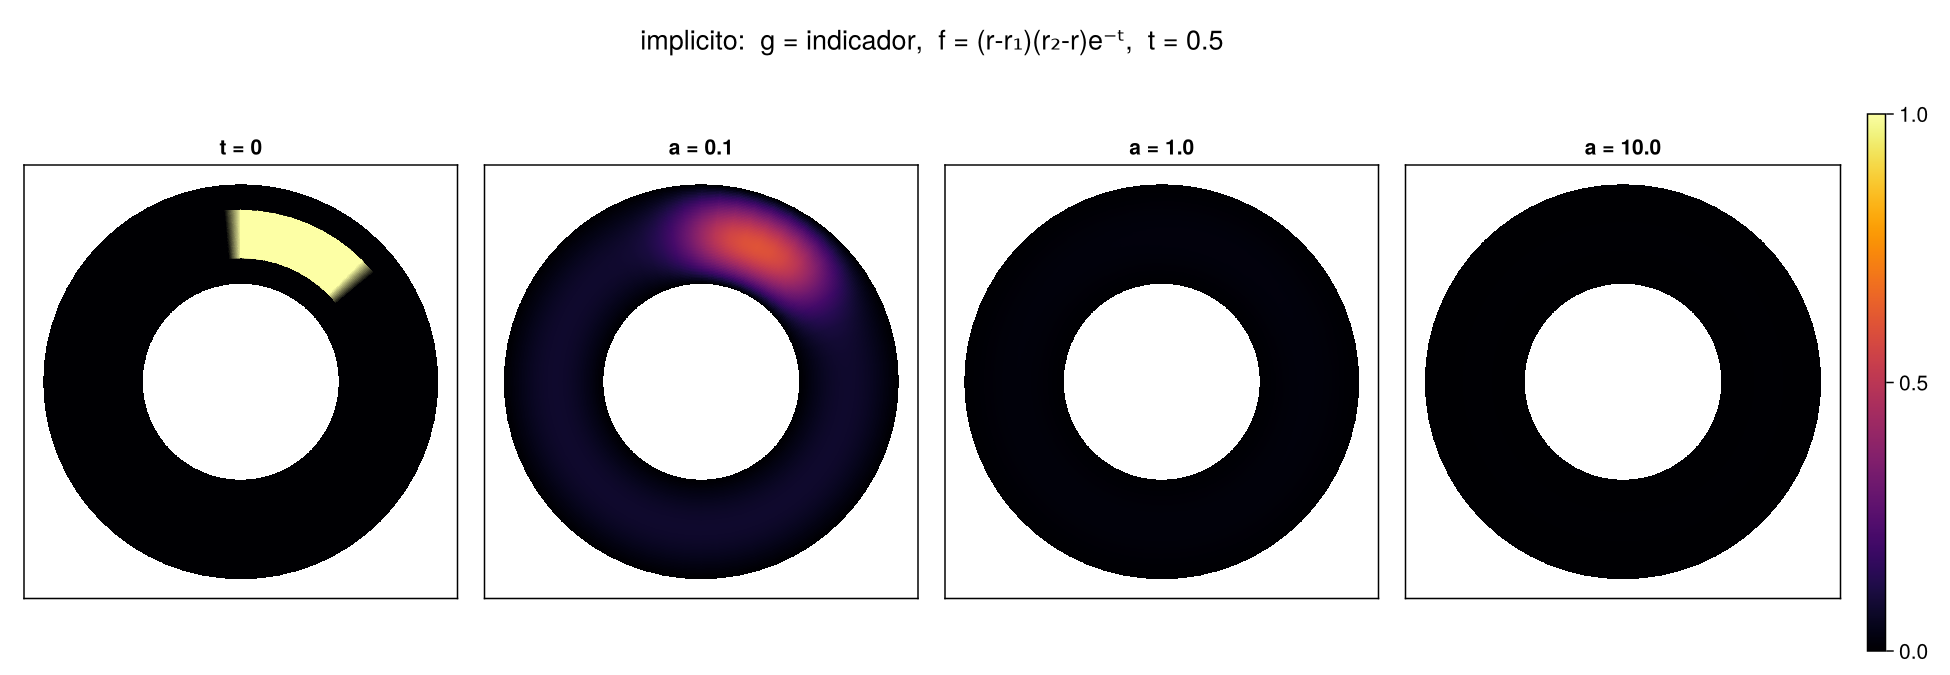

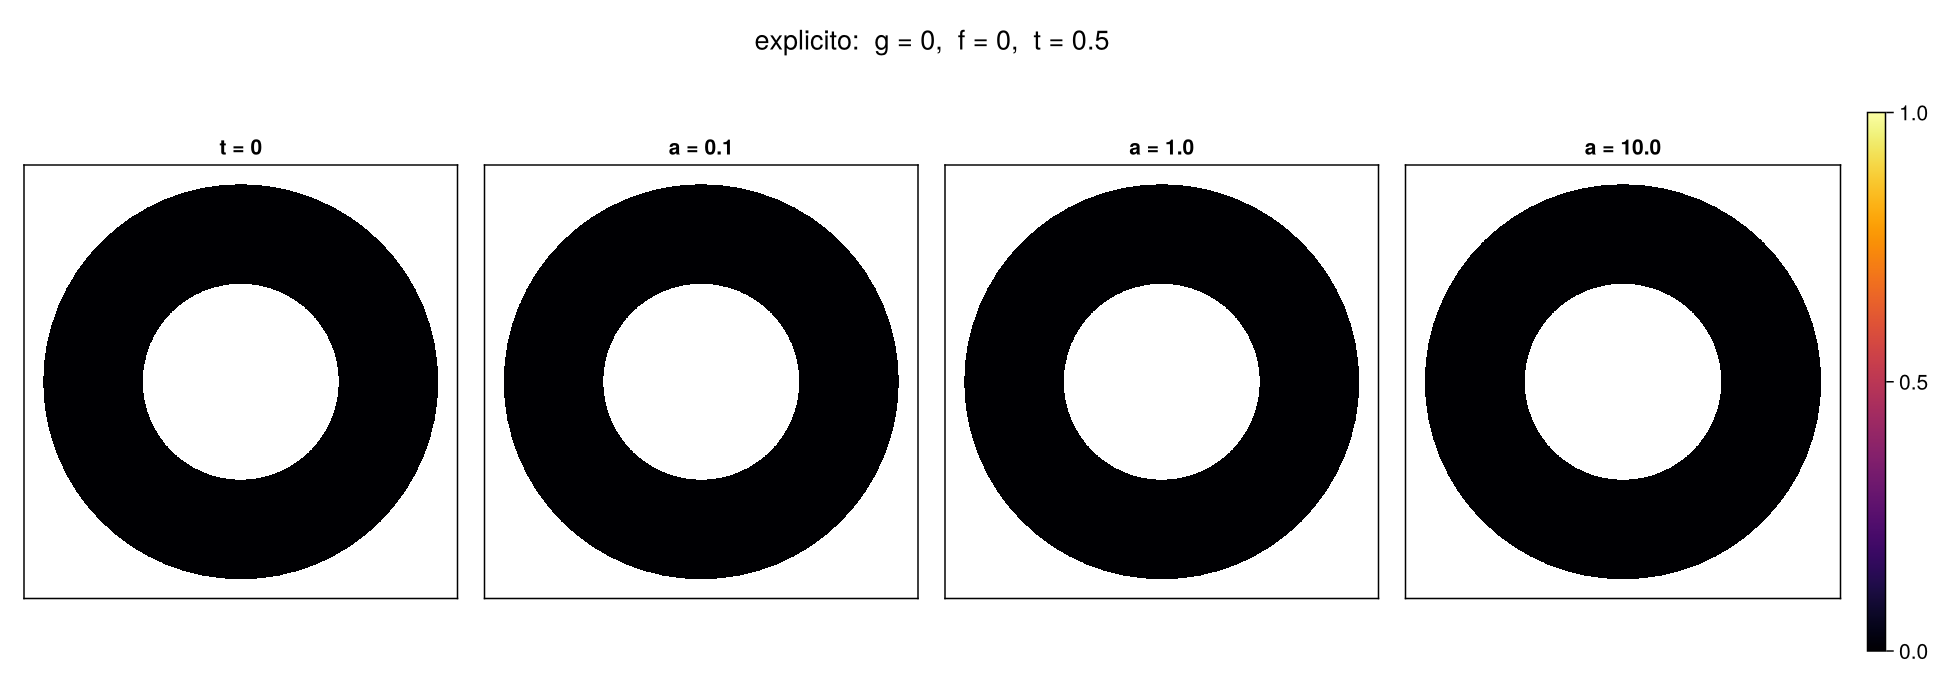

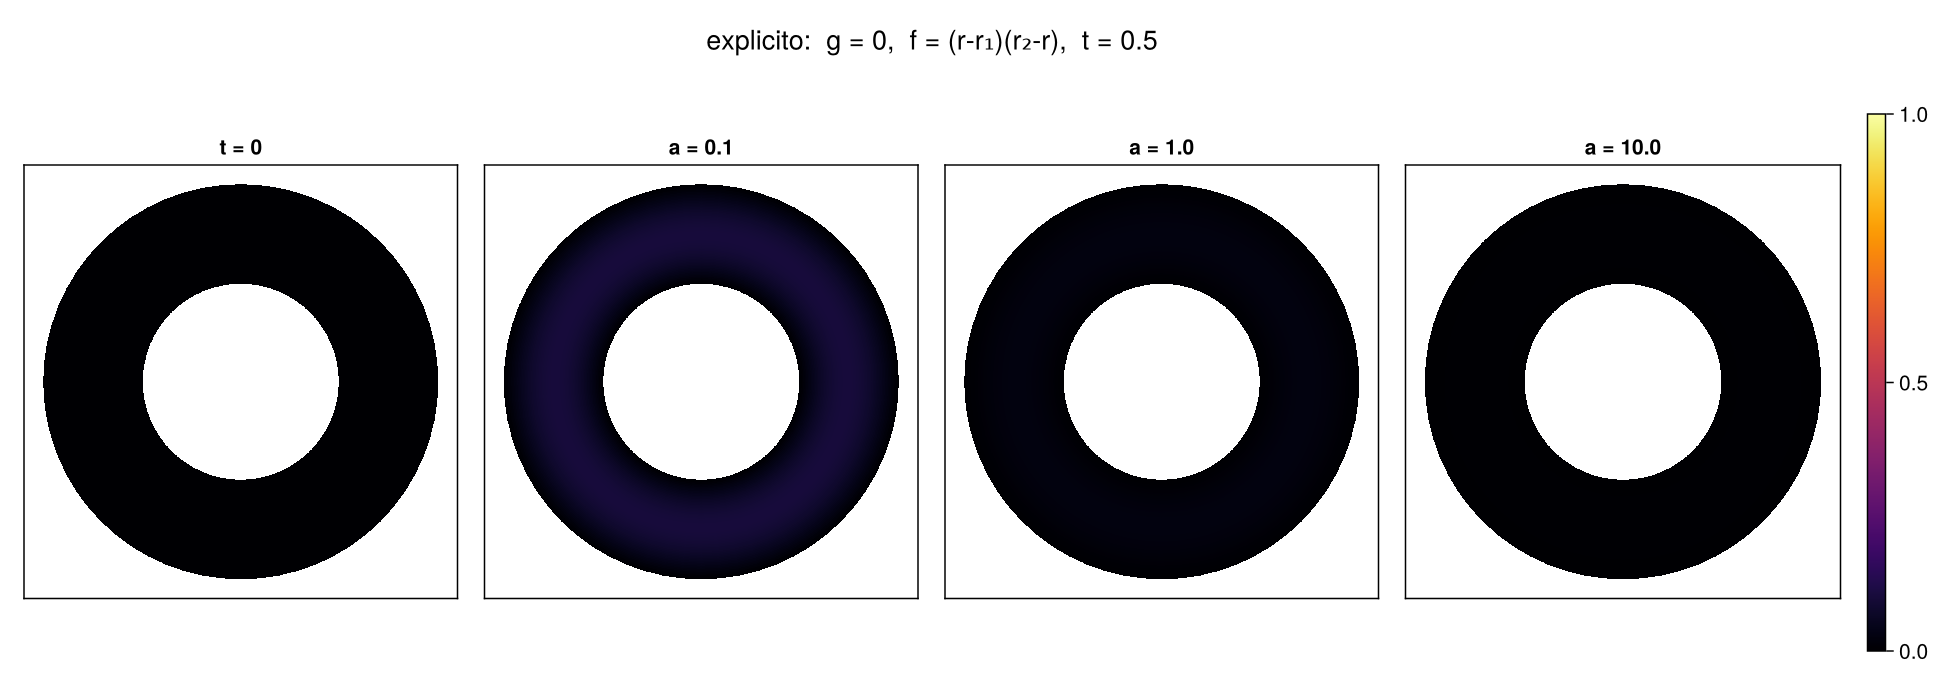

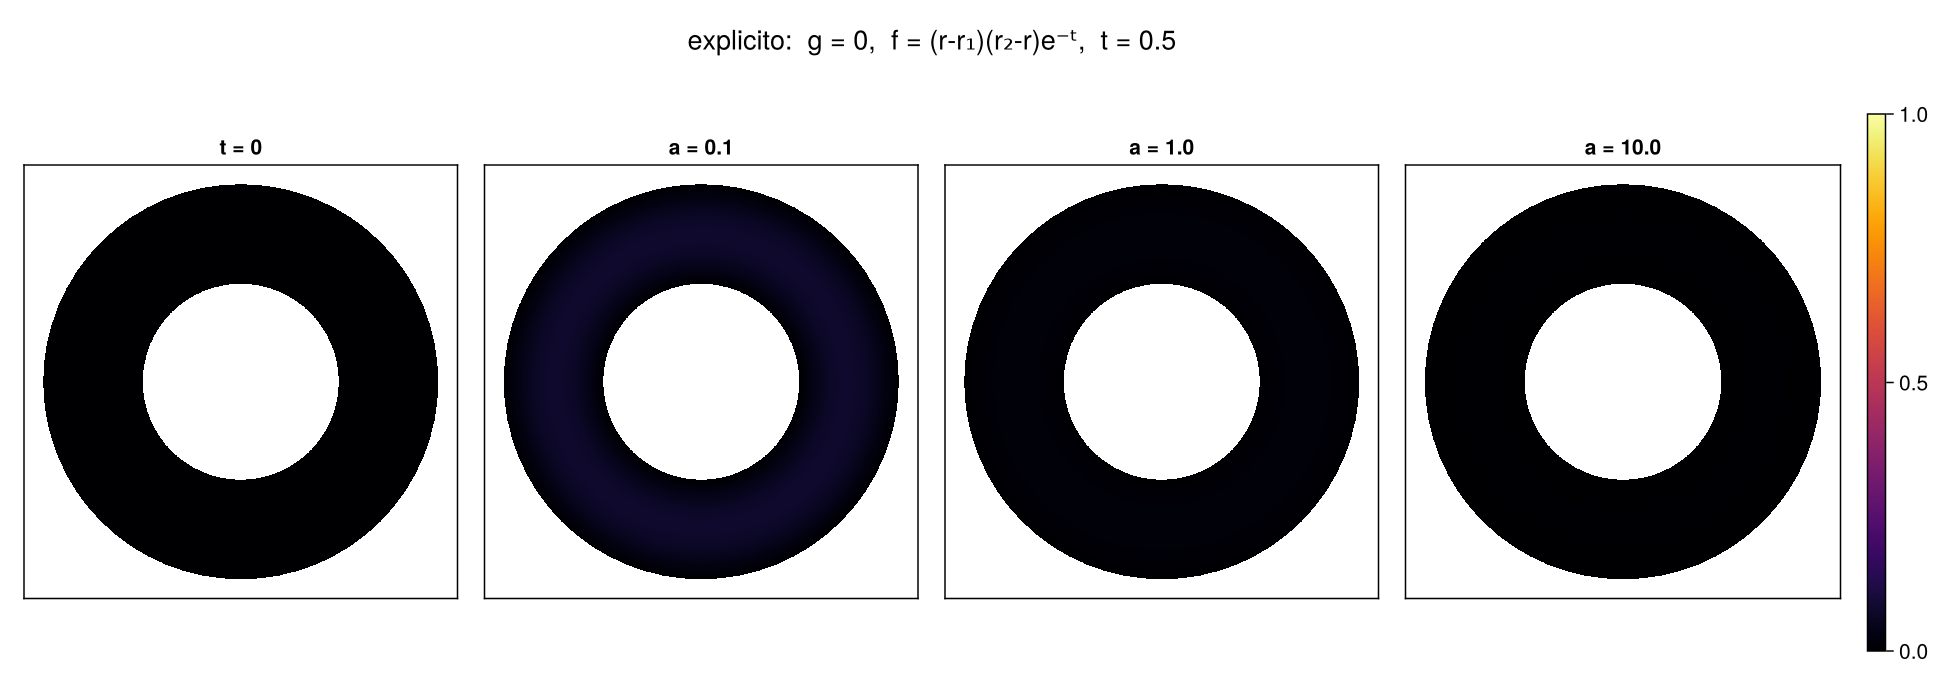

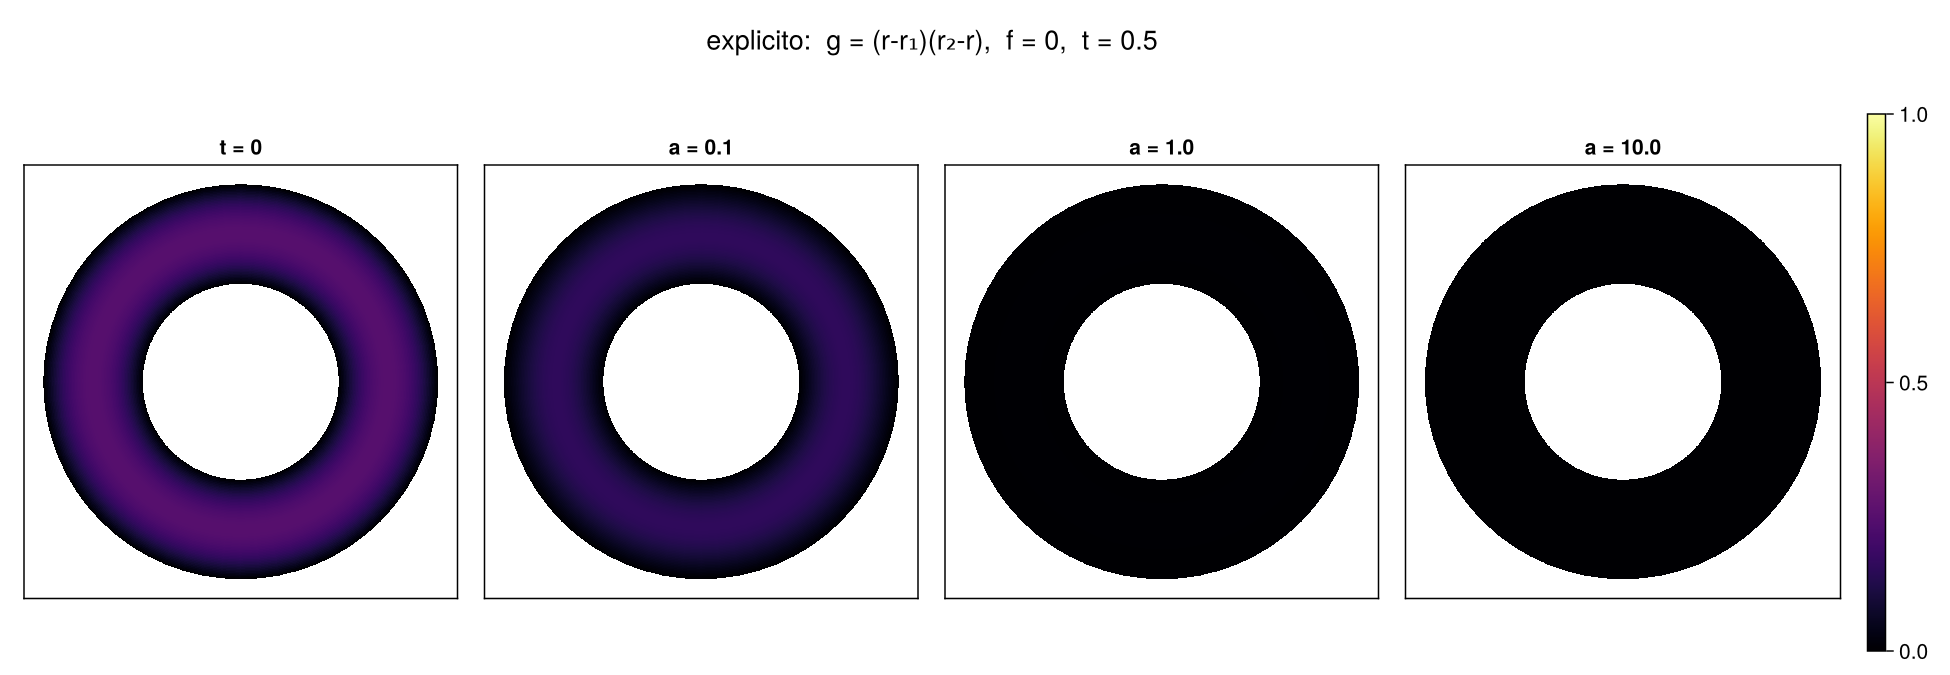

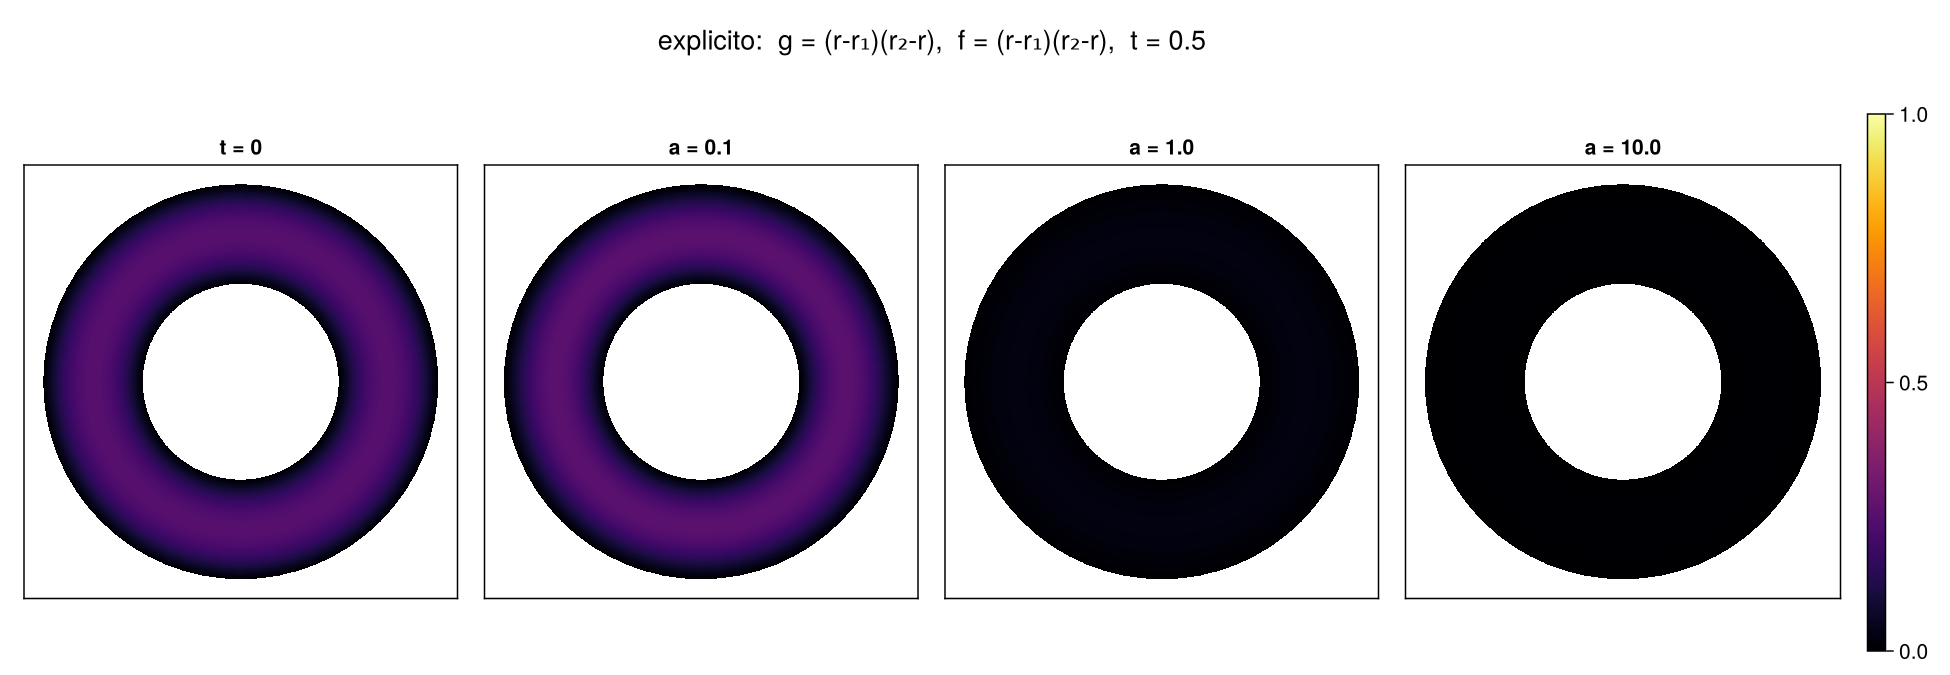

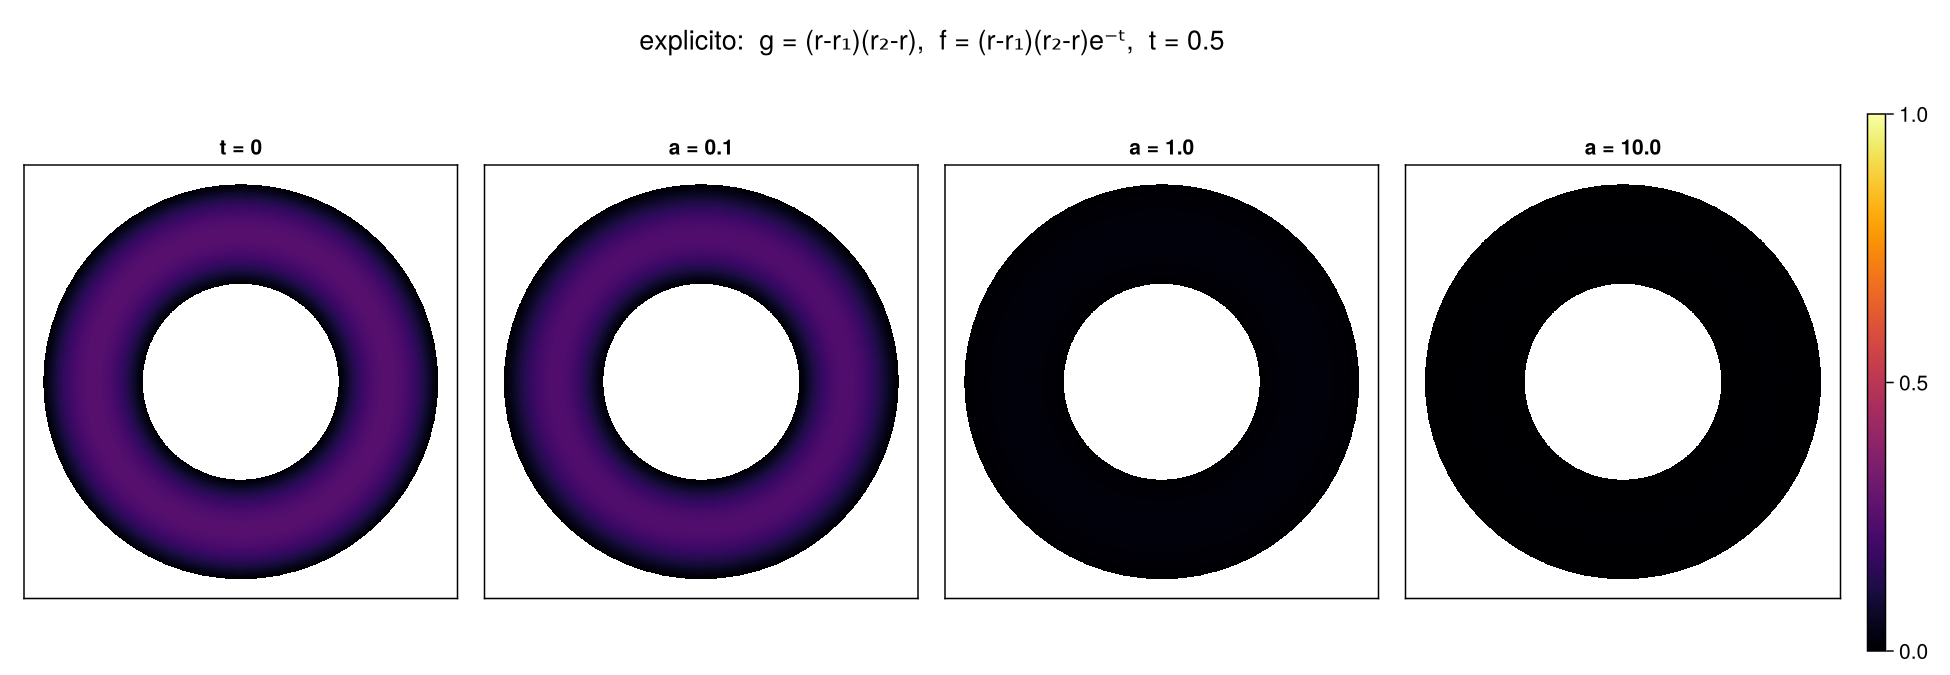

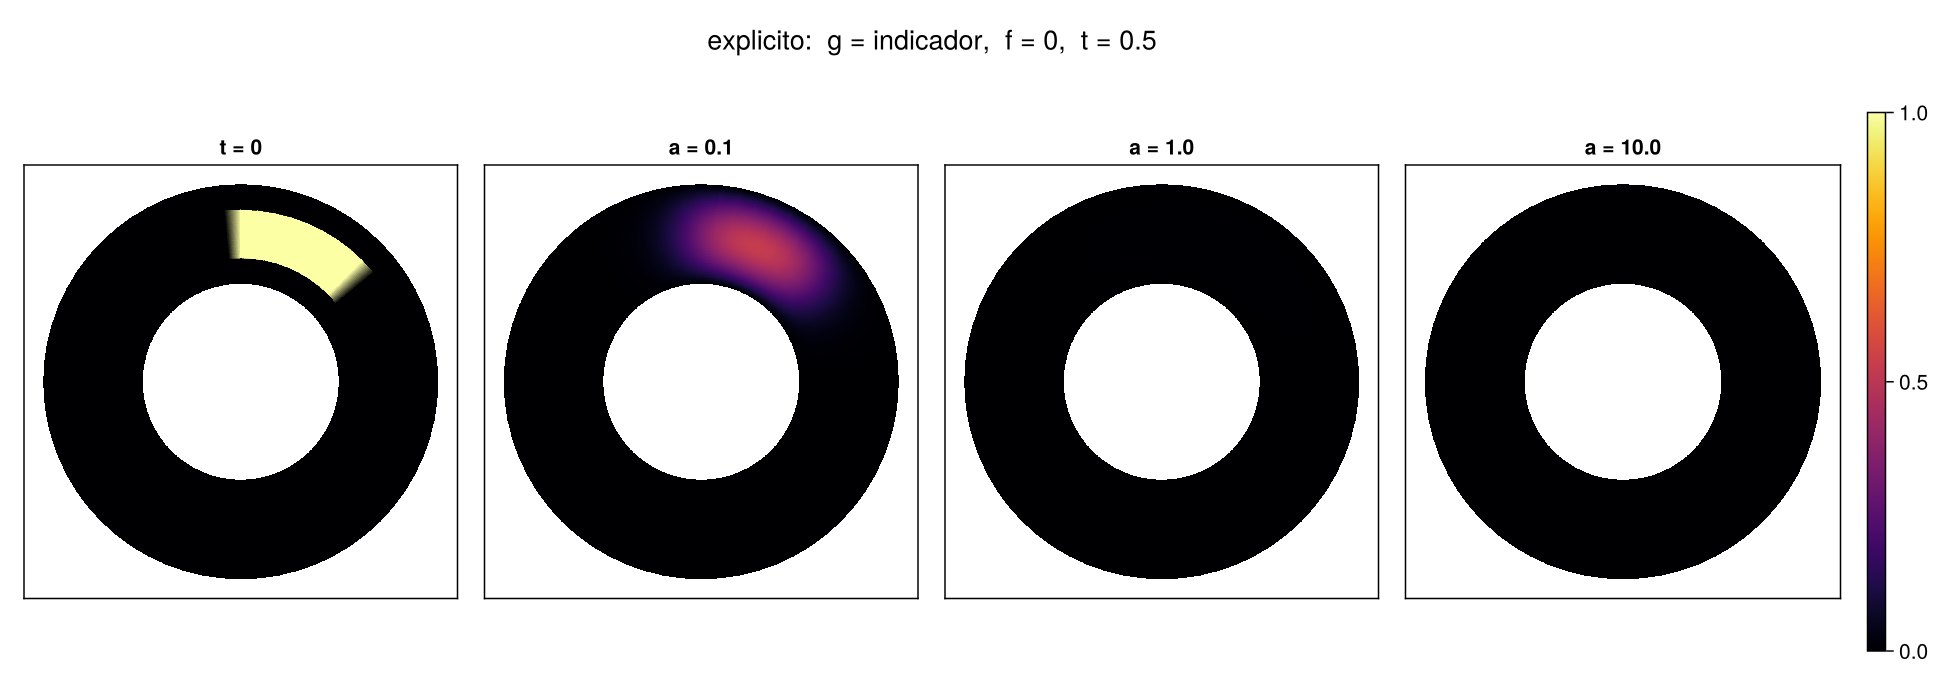

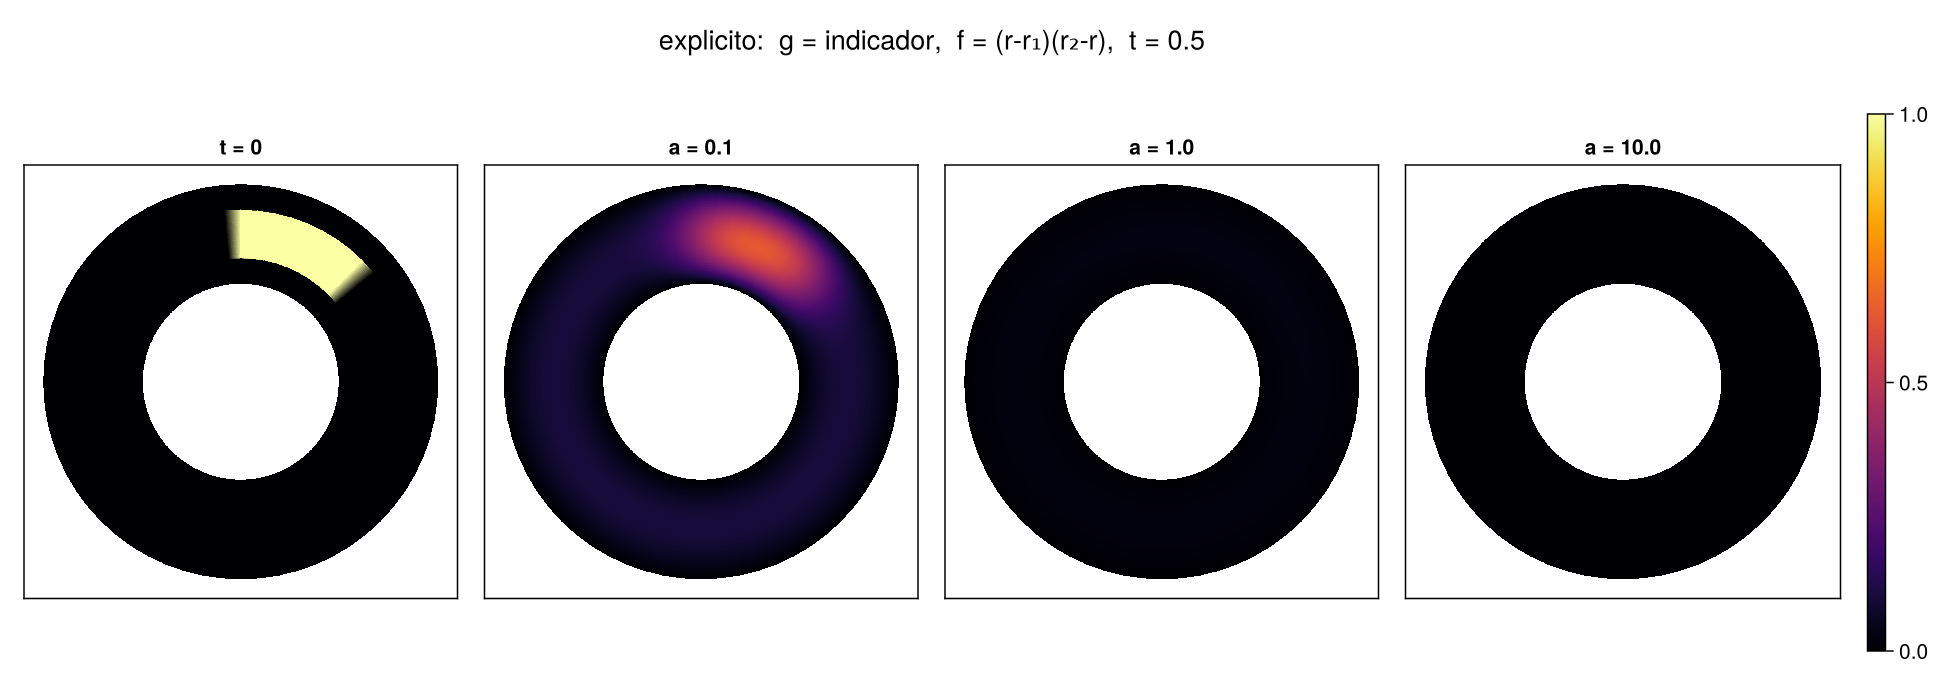

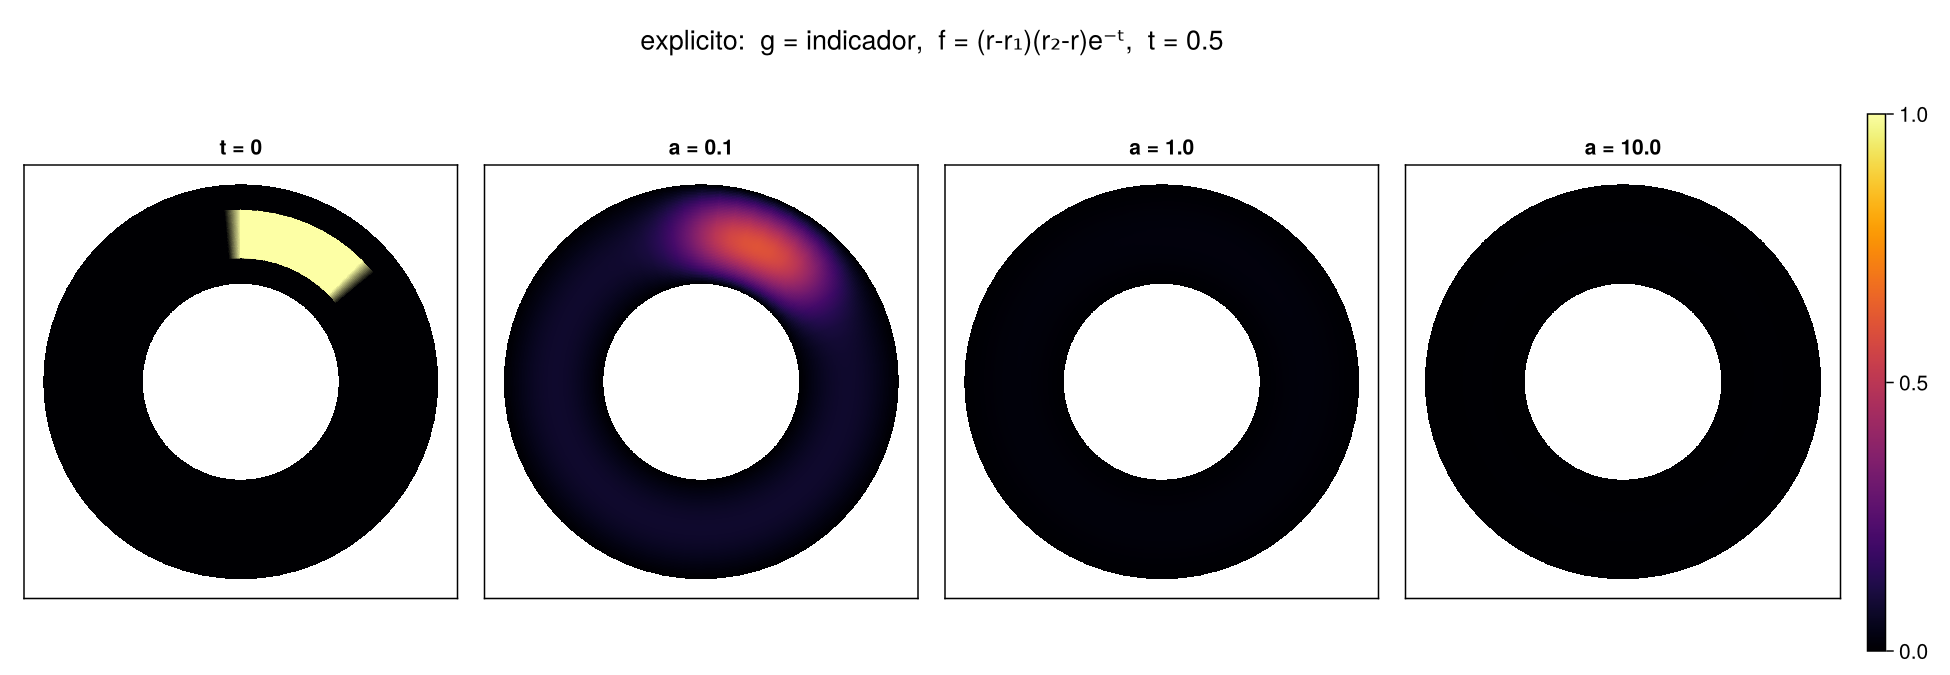

In [ ]:
# Construcción de K del método implícito
function build_K_implicito(rin, rout, N, a, dt)
    dr = (rout - rin) / (N + 1)
    dθ = 2π / N
    r  = [rin + i*dr for i in 1:N]

    # @. actua coordenada a coordenada (vectoriza)
    αp = @. 1/dr^2 + 1/(2*r*dr)
    αm = @. 1/dr^2 - 1/(2*r*dr)
    β  = @. 1/(r^2 * dθ^2)
    γ  = @. -2/dr^2 - 2*β

    # Elementos de la diagonal que acompañan a U_{i,j}^{n+1}
    main = @. 1 - a*dt*γ

    # Supradiagonal
    sup  = -a*dt .* αp[1:end-1]                  # A[i,i+1]

    # Subdiagonal
    sub  = -a*dt .* αm[2:end]                    # A[i,i-1]

    # OBS: 1:end-1 y 2:end es para que matcheen las dimensiones.

    # Arma una matriza esparsa (en este caso no completa lo que hay fuera de la diagonal)
    A = spdiagm(-1 => sub, 0 => main, 1 => sup)  # N×N
    B = spdiagm(β)                               # N×N

    # T
    T0 = spdiagm(-1 => ones(N-1), 1 => ones(N-1)) +
         sparse([1, N], [N, 1], [1.0, 1.0], N, N)
    T  = -a*dt * T0

    K = kron(sparse(I, N, N), A) + kron(T, B)
    return K, A, B, T, r
end

# Construcción de las matrices del método explícito
function build_explicito(rin, rout, N, a, dt)
    dr = (rout - rin) / (N + 1)
    dθ = 2π / N
    r  = [rin + i*dr for i in 1:N]

    # @. actua coordenada a coordenada (vectoriza)
    αp = @. 1/dr^2 + 1/(2*r*dr)
    αm = @. 1/dr^2 - 1/(2*r*dr)
    β  = @. 1/(r^2 * dθ^2)
    γ  = @. -2/dr^2 - 2*β

    # Elementos de la diagonal que acompañan a U_{i,j}^{n+1}
    main = @. 1 + a*dt*γ

    # Supradiagonal
    sup  = a*dt .* αp[1:end-1]                  # A[i,i+1]

    # Subdiagonal
    sub  = a*dt .* αm[2:end]                    # A[i,i-1]

    # OBS: 1:end-1 y 2:end es para que matcheen las dimensiones.

    # Arma una matriza esparsa (en este caso no completa lo que hay fuera de la diagonal)
    A = spdiagm(-1 => sub, 0 => main, 1 => sup)  # N×N
    B = spdiagm(β)                               # N×N

    # T
    T0 = spdiagm(-1 => ones(N-1), 1 => ones(N-1)) +
         sparse([1, N], [N, 1], [1.0, 1.0], N, N)
    T  = a*dt * T0

    return A, B, T, r
end

# Simulación
function simulate_implicito(g, f, a; N=N, dt=dt, nsteps=nsteps, rin=r1, rout=r2,
                  save_every=nsteps)

    K, A, B, T, r = build_K_implicito(rin, rout, N, a, dt)
    θ = [j * 2π / N for j in 0:N-1]

    U    = [g(ri, θj) for ri in r, θj in θ]       # N×N, filas = i, columnas = j
    fact = lu(K)                                  # se factoriza una sola vez

    # Arma vector "basura" del mismo tamaño.
    u    = similar(vec(U))

    # guardamos cada paso en res, en primer lugar tenemos el dato inicial.
    res = Dict{Int,Matrix{Float64}}(0 => copy(U))
    for n in 0:nsteps-1
        t  = (n + 1) * dt
        F  = [f(ri, θj, t) for ri in r, θj in θ]
        rhs = vec(U .+ dt .* F)
        ldiv!(u, fact, rhs)
        U = copy(reshape(u, N, N))
        if (n + 1) % save_every == 0
            res[n+1] = copy(U)
        end
    end
    return r, θ, U, res
end


# Simulación explícita
function simulate_explicito(g, f, a; N=N, dt=dt, nsteps=nsteps, rin=r1, rout=r2,
                            save_every=nsteps)

    dr   = (rout - rin) / (N + 1)
    dθ   = 2π / N

    A, B, T, r = build_explicito(rin, rout, N, a, dt)
    θ = [j * dθ for j in 0:N-1]

    U   = [g(ri, θj) for ri in r, θj in θ]
    res = Dict{Int,Matrix{Float64}}(0 => copy(U))

    for n in 0:nsteps-1
        t = n * dt
        F = [f(ri, θj, t) for ri in r, θj in θ]
        U = A*U + B*U*T + dt .* F
        if save_every > 0 && (n + 1) % save_every == 0
            res[n+1] = copy(U)
        end
    end
    return r, θ, U, res
end

# Resulta que para el explícito vamos a tener que refinar mas en el tiempo
# Más aún, va a depender de a
function simulate_explicito_a(g, f, a; Tf=Tfinal, kwargs...)
    dr = (r2 - r1) / (N + 1)
    dθ = 2π / N
    βmax  = 1 / ((r1 + dr)^2 * dθ^2)
    dtmax = 0.9 / (2*a*(1/dr^2 + βmax))
    ns = ceil(Int, Tf / dtmax)
    simulate_explicito(g, f, a; dt=Tf/ns, nsteps=ns, save_every=ns, kwargs...)
end


# Gráficos: se agregan bordes Dirichlet (ceros) y se cierra θ
function to_cartesian(r, θ, U, rin, rout)
    dr  = (rout - rin) / (N + 1)
    rf  = vcat(rin, r, rout)                      # N+2 radios
    θf  = vcat(θ, 2π)                             # cierra la vuelta
    Uf  = zeros(N + 2, N + 1)
    Uf[2:N+1, 1:N] .= U
    Uf[2:N+1, N+1] .= U[:, 1]                     # j = N ≡ j = 0
    X = [ri * cos(θj) for ri in rf, θj in θf]
    Y = [ri * sin(θj) for ri in rf, θj in θf]
    return X, Y, Uf
end

function plot_field!(ax, r, θ, U; colorrange=nothing)
    X, Y, Uf = to_cartesian(r, θ, U, r1, r2)
    lo, hi = colorrange === nothing ? extrema(Uf) : colorrange
    if hi - lo < 1e-12                      # campo constante (p.ej. todo cero)
        lo, hi = lo - 1e-3, hi + 1e-3
    end
    sf = surface!(ax, X, Y, zeros(size(X)); color=Uf, shading=NoShading,
                  colormap=:inferno, colorrange=(lo, hi))
    return sf
end

# Casos de prueba
gs = [("g = 0", g_zero), ("g = (r-r₁)(r₂-r)", g_parab), ("g = indicador", g_ind)]
fs = [("f = 0", f_zero), ("f = (r-r₁)(r₂-r)", f_parab), ("f = (r-r₁)(r₂-r)e⁻ᵗ", f_exp)]
as = [0.1, 1.0, 10.0]


# Elige el método y devuelve (r, θ, U_final, res) a tiempo Tfinal
function simular(metodo, g, f, a)
    if metodo == :implicito
        return simulate_implicito(g, f, a)               # dt y nsteps por defecto
    elseif metodo == :explicito
        return simulate_explicito_a(g, f, a)   # dt ajustado por estabilidad
    else
        error("método desconocido: $metodo (usá :implicito o :explicito)")
    end
end

# Simula todas las combinaciones y guarda los resultados
function compute_all()
    data = Dict{Tuple{Symbol,Int,Int},Any}()
    for metodo in (:implicito, :explicito),
        (ig, (gname, g)) in enumerate(gs),
        (jf, (fname, f)) in enumerate(fs)

        sims    = [simular(metodo, g, f, a) for a in as]
        r, θ    = sims[1][1], sims[1][2]
        results = [s[3] for s in sims]
        @assert all(U -> all(isfinite, U), results) "NaN/Inf en $metodo, g=$gname, f=$fname"

        U0 = [g(ri, θj) for ri in r, θj in θ]
        data[(metodo, ig, jf)] = (r, θ, U0, results)
    end
    return data
end

# Rango de color sobre un conjunto de casos (siempre incluye 0 por el borde Dirichlet)
function color_range(data, ks)
    lo, hi = 0.0, 0.0
    for k in ks
        _, _, U0, results = data[k]
        for U in (U0, results...)
            l, h = extrema(U)
            lo = min(lo, l); hi = max(hi, h)
        end
    end
    return (lo, hi)
end

# Dibuja un caso con un rango dado
function run_case(metodo, ig, jf, data, cr)
    gname, _ = gs[ig]
    fname, _ = fs[jf]
    r, θ, U0, results = data[(metodo, ig, jf)]

    fig = Figure(size=(1300, 450))
    Label(fig[0, 1:length(as)+1],
          "$metodo:  $gname,  $fname,  t = $Tfinal", fontsize=18)

    ax = Axis(fig[1, 1], aspect=DataAspect(), title="t = 0")
    hidedecorations!(ax)
    sf = plot_field!(ax, r, θ, U0; colorrange=cr)

    for (k, (a, U)) in enumerate(zip(as, results))
        ax = Axis(fig[1, k+1], aspect=DataAspect(), title="a = $a")
        hidedecorations!(ax)
        plot_field!(ax, r, θ, U; colorrange=cr)
    end
    Colorbar(fig[1, length(as)+2], sf)       # una sola barra, común a todos los paneles
    return fig
end

CairoMakie.activate!(type = "png", px_per_unit = 1.5)

# Simular
data = compute_all()

# Escala de colores global (más fácil de comparar las soluciones con distintos datos iniciales)
escala = :global

for metodo in (:implicito, :explicito), ig in eachindex(gs), jf in eachindex(fs)
    ks = escala == :global ? collect(keys(data)) :
         [k for k in keys(data) if k[2] == ig]
    cr = color_range(data, ks)
    display(run_case(metodo, ig, jf, data, cr))
end

Los gráficos muestran la configuración inicial y la solución a tiempo $t=0.5$ para los distintos valores de $a$.

## Ejercicio 3: estabilidad de von Neumann

En todo este ejercicio, $\mathbf{i}$ (en negrita) es la unidad imaginaria, e $i$ es el índice en $r$.

### Congelamiento del coeficiente

El método de von Neumann, tal como lo vimos, se aplica a esquemas con **coeficientes constantes**. Acá eso no pasa, porque $\alpha_i^\pm$, $\beta_i$ y $\gamma_i$ (definidos en la discretización) dependen de $r_i$. Siguiendo la consigna, **congelamos** $r_i=r$ fijo en esos coeficientes, que pasan a ser constantes: $\alpha^\pm$, $\beta$ y $\gamma$. Al final elegimos el $r$ más desfavorable de la malla.

Tomamos un modo $U_{i,j}=e^{\mathbf{i}(i\varphi+j\psi)}$, donde $\varphi\in[-\pi,\pi]$ es la frecuencia en $r$ y $\psi\in[-\pi,\pi]$ la frecuencia en $\theta$. Correrse un nodo en un índice multiplica por una exponencial:

$$
U_{i\pm1,j}=e^{\pm\mathbf{i}\varphi}\,U_{i,j},\qquad U_{i,j\pm1}=e^{\pm\mathbf{i}\psi}\,U_{i,j}.
$$

Reemplazando en $(L_hU)_{i,j}$ con los coeficientes congelados, todo queda multiplicado por $U_{i,j}$: $(L_hU)_{i,j}=\Lambda\,U_{i,j}$, con

$$
\Lambda=\alpha^-e^{-\mathbf{i}\varphi}+\alpha^+e^{\mathbf{i}\varphi}+\beta\,(e^{-\mathbf{i}\psi}+e^{\mathbf{i}\psi})+\gamma .
$$

**Parte radial.** Separamos $\alpha^\pm=\frac{1}{\Delta r^2}\pm\frac{1}{2r\Delta r}$ en sus dos sumandos:

$$
\alpha^-e^{-\mathbf{i}\varphi}+\alpha^+e^{\mathbf{i}\varphi}
=\frac{1}{\Delta r^2}\big(e^{\mathbf{i}\varphi}+e^{-\mathbf{i}\varphi}\big)+\frac{1}{2r\Delta r}\big(e^{\mathbf{i}\varphi}-e^{-\mathbf{i}\varphi}\big)
=\frac{2\cos\varphi}{\Delta r^2}+\mathbf{i}\,\frac{\sin\varphi}{r\Delta r}.
$$

**Parte angular.** $\beta\,(e^{-\mathbf{i}\psi}+e^{\mathbf{i}\psi})=2\beta\cos\psi$.

**Sumando $\gamma=-\frac{2}{\Delta r^2}-2\beta$** y usando $1-\cos x=2\sin^2\frac x2$:

$$
\Lambda=-\frac{4}{\Delta r^2}\sin^2\frac{\varphi}{2}-\frac{4}{r^2\Delta\theta^2}\sin^2\frac{\psi}{2}+\mathbf{i}\,\frac{\sin\varphi}{r\Delta r}.
$$

### Esquema explícito

Para estabilidad miramos el esquema sin fuente ($f=0$). Si comparamos dos soluciones con la misma $f$, al restarlas la $f$ se cancela. Queda

$$
U^{n+1}_{i,j}=U^n_{i,j}+a\Delta t\,(L_hU^n)_{i,j}.
$$

Proponemos $U^n_{i,j}=\xi^n e^{\mathbf{i}(i\varphi+j\psi)}$, donde $\xi$ es el factor de amplificación. Por la cuenta de $\Lambda$ de arriba, $(L_hU^n)_{i,j}=\Lambda\,U^n_{i,j}$. Reemplazando y dividiendo por $\xi^ne^{\mathbf{i}(i\varphi+j\psi)}$:

$$
\xi = 1 + a\Delta t\,\Lambda
= 1-\frac{4a\Delta t}{\Delta r^2}\sin^2\frac{\varphi}{2}-\frac{4a\Delta t}{r^2\Delta\theta^2}\sin^2\frac{\psi}{2}+\mathbf{i}\,\frac{a\Delta t}{r\Delta r}\sin\varphi .
$$

Definiendo

$$
\mu=\frac{a\Delta t}{\Delta r^2},\qquad \nu=\frac{a\Delta t}{r^2\Delta\theta^2},\qquad \kappa=\frac{a\Delta t}{r\Delta r},\qquad s=\sin^2\frac{\varphi}{2},\qquad q=\sin^2\frac{\psi}{2}.
$$

Queda

$$
\xi = 1-4\mu s-4\nu q+\mathbf{i}\,\kappa\sin\varphi .
$$

Los dos términos reales que restan son la difusión en $r$ y en $\theta$ durante un paso. Los agrupamos en

$$
X := 4\mu s+4\nu q \;\ge 0 ,
$$

que es $\ge 0$ porque $\mu,\nu,s,q\ge0$. Entonces $\xi=(1-X)+\mathbf{i}\,\kappa\sin\varphi$ tiene parte real $1-X$ y parte imaginaria $\kappa\sin\varphi$, y por lo tanto

$$
|\xi|^2=(1-X)^2+\kappa^2\sin^2\varphi .
$$

Recordemos que el esquema es estable si $\|w^m\|\le C\|w^0\|$ para $m\Delta t\le T$, con $C$ **independiente de la malla**. En términos de $\xi$, esto permite que $|\xi|$ sea apenas mayor que $1$: si $|\xi|\le 1+K\Delta t$, entonces $|\xi|^m\le(1+K\Delta t)^{T/\Delta t}\le e^{KT}$, que es una constante. Lo que no se puede es $|\xi|\ge c>1$ fijo, porque $c^m$ explota.

**La parte imaginaria es de orden $\Delta t$.** Como $\kappa^2=\dfrac{a^2\Delta t^2}{r^2\Delta r^2}=\mu\cdot\dfrac{a\Delta t}{r^2}$, si $\mu\le\frac12$ vale $\kappa^2\sin^2\varphi\le\dfrac{a}{2r^2}\,\Delta t$. Entonces

$$
|\xi|^2\le(1-X)^2+\frac{a}{2r^2}\,\Delta t ,
$$

Si además $|1-X|\le1$, queda $|\xi|^2\le1+\frac{a}{2r^2}\Delta t$, y entonces $|\xi|\le1+\frac{a}{4r^2}\Delta t$ (porque $\sqrt{1+x}\le1+\frac x2$), que es justo lo que permite la definición. Así que la parte imaginaria no afecta la estabilidad y sólo hay que pedir $|1-X|\le1$.

$$
-1\le 1-X\le 1 \iff 0\le X\le 2 .
$$

$X\ge0$ siempre. $X$ es máximo cuando $s=q=1$, es decir $\varphi=\psi=\pi$, y ahí vale $4(\mu+\nu)$. La condición es entonces $4(\mu+\nu)\le2$, o sea $\mu+\nu\le\frac12$ (que en particular da $\mu\le\frac12$, lo que usamos arriba):

$$
\boxed{\;\Delta t\;\le\;\Delta t^*(r) := \frac{1}{2a\left(\dfrac{1}{\Delta r^2}+\dfrac{1}{r^2\Delta\theta^2}\right)}\;}
$$

Veamos que es condición necesaria. Si $\varphi=\psi=\pi$, $\xi=1-4(\mu+\nu)$. Si $\mu+\nu>\frac12$, entonces $\xi<-1$.

- $\Delta t^*(r)$ crece con $r$, así que la condición más restrictiva está en el radio más chico de la malla, que es el primer nodo interior $r_1=r_{\rm in}+\Delta r$ (los nodos $r_0=r_{\rm in}$ y $r_{N+1}=r_{\rm out}$ son de borde y no se actualizan):
$$
\Delta t \le \Delta t^* := \Delta t^*(r_1) = \frac{1}{2a\left(\dfrac{1}{\Delta r^2}+\dfrac{1}{r_1^2\,\Delta\theta^2}\right)} .
$$

Este $\Delta t^*$, sin argumento, es el paso crítico de toda la malla: el que usamos de referencia en los experimentos (en el código, `dt_vn_malla`).

### Esquema implícito

Seguimos los mismos pasos que en el explícito. La única diferencia es que el laplaciano discreto se evalúa en el tiempo **nuevo** $n+1$, en lugar de en el tiempo $n$.

**El esquema.** Sin fuente ($f=0$):

$$
\frac{U^{n+1}_{i,j}-U^n_{i,j}}{\Delta t}=a\,(L_hU^{n+1})_{i,j}.
$$

Multiplicamos por $\Delta t$ y pasamos a la izquierda todo lo que está en el tiempo $n+1$:

$$
U^{n+1}_{i,j}-a\Delta t\,(L_hU^{n+1})_{i,j}=U^n_{i,j}.
$$

**El modo de Fourier.** Proponemos de nuevo $U^n_{i,j}=\xi^n e^{\mathbf{i}(i\varphi+j\psi)}$. La cuenta de $\Lambda$ vale para cualquier onda, así que también para la del tiempo $n+1$: $(L_hU^{n+1})_{i,j}=\Lambda\,U^{n+1}_{i,j}$. Reemplazando,

$$
\xi^{n+1}e^{\mathbf{i}(i\varphi+j\psi)}-a\Delta t\,\Lambda\,\xi^{n+1}e^{\mathbf{i}(i\varphi+j\psi)}=\xi^{n}e^{\mathbf{i}(i\varphi+j\psi)} .
$$

Dividimos por $\xi^n e^{\mathbf{i}(i\varphi+j\psi)}$ y sacamos $\xi$ de factor común:

$$
\xi\,(1-a\Delta t\,\Lambda)=1
\qquad\Longrightarrow\qquad
\xi=\frac{1}{1-a\Delta t\,\Lambda}.
$$

En el explícito, $\Lambda$ estaba en el numerador ($\xi=1+a\Delta t\,\Lambda$). En el implícito está en el denominador.

**Reemplazar $a\Delta t\,\Lambda$.** Esta cuenta ya está hecha en el esquema explícito: allí vimos que $1+a\Delta t\,\Lambda = 1-X+\mathbf{i}\,\kappa\sin\varphi$, es decir

$$
a\Delta t\,\Lambda=-X+\mathbf{i}\,\kappa\sin\varphi ,
$$

con los mismos $X=4\mu s+4\nu q\ge0$ y $\kappa=\frac{a\Delta t}{r\Delta r}$. Entonces $1-a\Delta t\,\Lambda=1+X-\mathbf{i}\,\kappa\sin\varphi$, y

$$
\xi=\frac{1}{1+X-\mathbf{i}\,\kappa\sin\varphi}.
$$


$$
|\xi|^2=\frac{1}{(1+X)^2+\kappa^2\sin^2\varphi}.
$$

El denominador es una suma de dos cosas:

- $(1+X)^2\ge1$, porque $X\ge0$;
- $\kappa^2\sin^2\varphi\ge0$, porque es un cuadrado.

Entonces el denominador es $\ge1$, y por lo tanto $|\xi|^2\le1$ para toda frecuencia $\varphi,\psi$. En ningún momento usamos una condición sobre $\Delta t$, $\Delta r$, $\Delta\theta$ ni $r$: el esquema implícito es **incondicionalmente estable**.


In [ ]:
using Printf

# ---------- Ejercicio 3: estabilidad ----------

# Δt crítico de von Neumann con 1/r congelado en r
dt_vn(dr, dθ, r, a) = 1 / (2a * (1/dr^2 + 1/(r^2 * dθ^2)))

# Δt crítico para toda la malla: peor caso en el primer nodo interior, r_1 = rin + Δr
function dt_vn_malla(Nv, a; rin=r1, rout=r2)
    dr = (rout - rin) / (Nv + 1)
    dθ = 2π / Nv
    return dt_vn(dr, dθ, rin + dr, a)
end

for a in as
    @printf("a = %5.1f   Δt* (N = %d) = %.4e\n", a, N, dt_vn_malla(N, a))
end

a =   0.1   Δt* (N = 64) = 1.1559e-03
a =   1.0   Δt* (N = 64) = 1.1559e-04
a =  10.0   Δt* (N = 64) = 1.1559e-05


### Verificación experimental (1): paso crítico de la matriz completa

Comparamos $\Delta t^*$ con el paso crítico de la iteración explícita sin congelar el coeficiente, $U^{n+1}=(I+a\Delta t\,L_h)U^n$. Los autovalores $\lambda$ de $L_h$ son reales y negativos, así que ningún autovector se amplifica si $|1+a\Delta t\,\lambda|\le1$ para todo $\lambda$, es decir, si

$$
\Delta t\le \Delta t_{\rm esp} = \frac{2}{a\,|\lambda_{\min}(L_h)|}.
$$

Para calcular los autovalores usamos que, como la malla es periódica en $\theta$ y los coeficientes no dependen de $j$, $L_h$ se separa en $N$ bloques tridiagonales, uno por cada frecuencia $l$ en $\theta$: $\mathrm{tridiag}\big(\alpha_i^-,\ \gamma_i+2\beta_i\cos(2\pi l/N),\ \alpha_i^+\big)$.

In [ ]:
function λmin_Lh(Nv; rin=r1, rout=r2)
    dr = (rout - rin) / (Nv + 1)
    dθ = 2π / Nv
    r  = [rin + i*dr for i in 1:Nv]
    αp = @. 1/dr^2 + 1/(2*r*dr)
    αm = @. 1/dr^2 - 1/(2*r*dr)
    β  = @. 1/(r^2 * dθ^2)
    γ  = @. -2/dr^2 - 2*β
    λmin = 0.0
    for l in 0:Nv-1
        D = Tridiagonal(αm[2:end], γ .+ 2 .* β .* cos(2π*l/Nv), αp[1:end-1])
        λmin = min(λmin, minimum(real.(eigvals(Matrix(D)))))
    end
    return λmin
end

let a = 1.0
    println("   N     Δt* von Neumann    Δt espectral     cociente")
    for Nv in (16, 32, 64, 128)
        dvn = dt_vn_malla(Nv, a)
        des = 2 / (a * abs(λmin_Lh(Nv)))
        @printf("%4d     %.6e     %.6e     %.4f\n", Nv, dvn, des, des/dvn)
    end
end

   N     Δt* von Neumann    Δt espectral     cociente
  16     1.696157e-03     1.726133e-03     1.0177
  32     4.490608e-04     4.545677e-04     1.0123
  64     1.155900e-04     1.166454e-04     1.0091
 128     2.932611e-05     2.951361e-05     1.0064


En la tabla, $\Delta t_{\rm esp}$ es apenas mayor que $\Delta t^*$, y la diferencia se achica al refinar la malla: la cota obtenida congelando el coeficiente coincide con la de la matriz completa y es levemente más restrictiva. El cociente no depende de $a$, porque los dos pasos son proporcionales a $1/a$.

### Verificación experimental (2): evolución de $\max|U^n|$

Corremos ambos esquemas con $f=0$, $N=64$ y dato inicial indicador (que, por sus saltos, tiene componentes en todas las frecuencias), para varios múltiplos $c$ de $\Delta t^*$. Con $f=0$ y Dirichlet homogéneo la solución exacta decae, así que si $\max|U^n|$ crece es por inestabilidad. Tomamos sólo $a=1$: con $f=0$, $a$ y $\Delta t$ aparecen sólo como $a\Delta t$, así que otro valor de $a$ da las mismas curvas con el tiempo reescalado.

explícito  a= 1.0  c= 0.90  pasos= 481  max|U| final = 5.282e-01
explícito  a= 1.0  c= 1.00  pasos= 433  max|U| final = 5.281e-01
explícito  a= 1.0  c= 1.05  pasos= 313  max|U| final = 1.002e+08
explícito  a= 1.0  c= 1.10  pasos= 145  max|U| final = 1.129e+08
implícito  a= 1.0  c=    1  pasos= 433  max|U| máx = 1.000e+00
implícito  a= 1.0  c=   10  pasos=  43  max|U| máx = 1.000e+00
implícito  a= 1.0  c=  100  pasos=   4  max|U| máx = 1.000e+00
implícito  a= 1.0  c= 1000  pasos=   3  max|U| máx = 1.000e+00


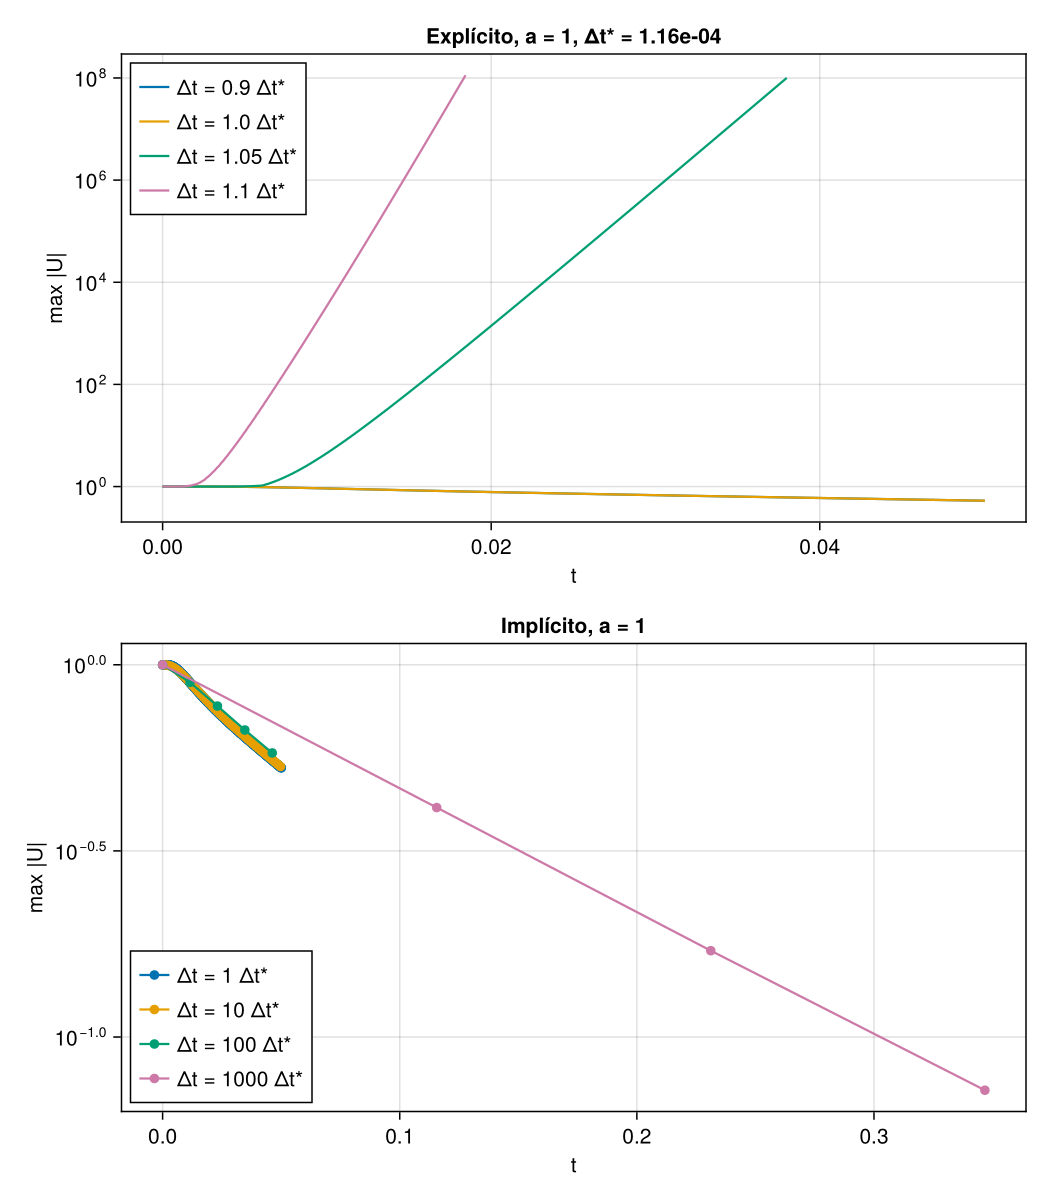

CairoMakie.Screen{IMAGE}


In [ ]:
function historia_explicito(g, a, dt, Tf; Nv=64, rin=r1, rout=r2, cota=1e8)
    A, B, T, r = build_explicito(rin, rout, Nv, a, dt)
    θ  = [j * 2π / Nv for j in 0:Nv-1]
    U  = [g(ri, θj) for ri in r, θj in θ]
    ns = round(Int, Tf / dt)
    ts = [0.0];  M = [maximum(abs, U)]
    for n in 1:ns
        U = A*U + B*U*T                      # f = 0
        push!(ts, n*dt);  push!(M, maximum(abs, U))
        M[end] > cota && break               # cortamos si explotó
    end
    return ts, M
end

function historia_implicito(g, a, dt, Tf; Nv=64, rin=r1, rout=r2)
    K, _, _, _, r = build_K_implicito(rin, rout, Nv, a, dt)
    fact = lu(K)
    θ  = [j * 2π / Nv for j in 0:Nv-1]
    u  = vec([g(ri, θj) for ri in r, θj in θ])
    ns = max(1, round(Int, Tf / dt))
    ts = [0.0];  M = [maximum(abs, u)]
    for n in 1:ns
        u = fact \ u                         # f = 0
        push!(ts, n*dt);  push!(M, maximum(abs, u))
    end
    return ts, M
end

let Nv = 64
    fig = Figure(size=(700, 800))
    for (col, a) in enumerate((1.0,))
        dtc = dt_vn_malla(Nv, a)
        Tf  = 0.05 / a

        ax = Axis(fig[1, col], yscale=log10, xlabel="t", ylabel="max |U|",
                  title=@sprintf("Explícito, a = %.0f, Δt* = %.2e", a, dtc))
        for c in (0.9, 1.0, 1.05, 1.1)
            ts, M = historia_explicito(g_ind, a, c*dtc, Tf; Nv)
            lines!(ax, ts, M, label="Δt = $(c) Δt*")
            @printf("explícito  a=%4.1f  c=%5.2f  pasos=%4d  max|U| final = %.3e\n", a, c, length(ts)-1, M[end])
        end
        axislegend(ax, position=:lt)

        ax = Axis(fig[2, col], yscale=log10, xlabel="t", ylabel="max |U|",
                  title=@sprintf("Implícito, a = %.0f", a))
        for c in (1, 10, 100, 1000)
            ts, M = historia_implicito(g_ind, a, c*dtc, max(Tf, 3c*dtc); Nv)
            scatterlines!(ax, ts, M, label="Δt = $(c) Δt*")
            @printf("implícito  a=%4.1f  c=%5d  pasos=%4d  max|U| máx = %.3e\n", a, c, length(ts)-1, maximum(M))
        end
        axislegend(ax, position=:lb)
    end
    display(fig)
end

### Conclusiones

El esquema explícito se mantiene acotado para $c=0.9$ y $c=1$, y explota para $c=1.05$ y $c=1.1$, como predice la condición $\Delta t\le\Delta t^*$. El implícito no crece para ninguno de los valores probados (hasta $c=1000$), como predice su estabilidad incondicional.